# 02 · Descriptivo del surtido

Qué vende la tienda a lo largo de los **31 meses** del diario de ventas por
artículo: de qué productos se compone el surtido, cuánto dura cada uno en el
lineal, con qué margen se venden y cómo ha evolucionado la facturación una vez
descontada la inflación.

Trabaja sobre `datos_limpio/consolidado_mensual.parquet`, una fila por artículo
y mes, sin IVA. Qué significa cada tipo de fila y qué trampas tiene el fichero
está en [`01-exploracion-datos.ipynb`](01-exploracion-datos.ipynb).

> **La base de coste es `tarifa_costo`**, no `costo_medio`, que se descartó
> contrastándolo con un dato externo al programa: la ficha del aceite de
> girasol que facilitó la tienda da **1,53 € de coste de cesión** donde
> `costo_medio` marcaba entre 2,21 € y 3,13 €. Todo lo que este notebook llama
> *margen* es **margen teórico sobre tarifa**: el coste que consta en la
> **ficha** del artículo —la tarifa del proveedor—, no una compra observada. Y
> es margen sobre la **mercancía**: sin alquiler, sueldos, luz ni
> amortizaciones. Un 28 % de margen no es un 28 % de beneficio para la tienda.

**Conclusiones principales:**
- El margen sobre la mercancía es del **28,38 %** y sube de 2024 a 2026.
- Los artículos fijos rinden más que los que rotan.
- El producto fresco supera el 30 % de los ingresos, la referencia del sector.

**Cada apartado usa la ventana que responde a su pregunta** y lo dice en su
texto; las figuras la llevan en el nombre del fichero.

In [1]:
import sys

sys.path.insert(0, "../src")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

GUARDAR_FIGURAS = True                 # exporta a reports/figuras/ en PNG 150dpi + SVG
FIGURAS = Path("../reports/figuras")

# --- Parámetros de ventana ------------------------------------------------
MESES_AÑO_MOVIL = 12                  # el año móvil reciente: el surtido de hoy (§4.6)

# Venta mínima de un departamento en el año móvil para salir en la figura de
# margen por departamento (§4.3).
VENTA_MIN_DPTO_FIGURA = 1000

# --- Base de coste ----------------------------------------------
BASE_COSTE = "tarifa_costo"

# Coste disparatado: más de 10 veces el precio de venta.
RATIO_COSTE_ABSURDO = 10

# Los dos códigos de bolsa camiseta.
BOLSAS_CAJA = ["121601", "121602"]

# Excluir del surtido las filas artículo×mes que el informe da por debajo de
# coste y que son un defecto de la columna de coste, no una venta.
EXCLUIR_ERRORES_BC = True

# Departamentos de producto fresco (§5).
DEP_FRESCOS = ["CARNICERIA", "CARNICERIA L.S", "CHARCUTERIA CORTE",
               "CHARCUTERIA L.S", "FRUTAS Y VERDURAS", "PANADERIA PASTELERIA",
               "PESCADO Y MARISCO", "L.S CARNICO Y SALAZONES"]

# Los códigos de bebida fría (§7). El §7 mide su diferencial imputándoles el
# coste del mismo envase en el lineal.
FRIOS_BEBIDA = ["84887", "84891", "84888", "84890", "84886", "84889", "85695"]
FRIOS_SUPLEMENTO = ["80006", "80768"]   # no son mercancía: recargo por servicio
FRIOS_TODOS = FRIOS_BEBIDA + FRIOS_SUPLEMENTO

# Deflactor: IPC de alimentos de Almería, a impuestos constantes, mismo
# criterio que la serie semanal. Ver §6.
IPC_AMBITO = "almeria"
IPC_CONCEPTO = "alimentos_bebidas_no_alc"

AZUL = "#2a78d6"
NARANJA = "#d97528"
VERDE = "#3d9970"
MORADO = "#8e44ad"
TINTA = "#0b0b0b"
TINTA_SEC = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.labelcolor": TINTA_SEC,
    "xtick.color": TINTA_SEC,
    "ytick.color": TINTA_SEC,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


def num(valor, dec=2, signo=False):
    """Convención española: millares con punto, decimales con coma (5.355,29).

    Mismo helper que el notebook 01. El TPV escribe los números al revés; eso
    es cómo llega el dato, no cómo se presenta.
    """
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "—"
    crudo = f"{valor:{'+' if signo else ''},.{dec}f}"
    return crudo.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


pd.options.display.float_format = num


def margen_ponderado(g):
    """Margen en euros total / venta total, en %. nunca la media de los porcentajes.

    Qué es: el margen en euros es la venta menos lo que costó comprar ese mismo stock
   (`unidades` x `tarifa_costo`). Sobre la base de margen cuadra con el
    `beneficio_tc` que emite el TPV al 0,03 %, y el residuo es el redondeo del
    coste a dos decimales.

    Qué no es: rentabilidad del negocio. Aquí no hay alquiler, sueldos, luz ni
    amortizaciones - solo la mercancía.

    Y cuidado con el porcentaje: va sobre la venta, no sobre el coste. Es lo que hace
    engañoso el campo `%Rent.C.M.` del informe, que se lee "rentabilidad sobre
    coste medio" y es beneficio/venta.

    Se pondera por venta y no se promedian porcentajes (agregación de
    porcentajes de rentabilidad): la media simple da el mismo peso a un
    artículo que vende 3 € que a uno que vende 3.000 €.
    """
    if g.empty or g["total_venta"].sum() == 0:
        return np.nan
    return 100 * g["beneficio_tc"].sum() / g["total_venta"].sum()


def guardar(fig, nombre, ventana):
    """Exporta la figura con la ventana en el nombre del fichero."""
    if not GUARDAR_FIGURAS:
        return
    FIGURAS.mkdir(parents=True, exist_ok=True)
    base = FIGURAS / f"02-{nombre}-{ventana}"
    fig.savefig(base.with_suffix(".png"), dpi=150, bbox_inches="tight")
    fig.savefig(base.with_suffix(".svg"), bbox_inches="tight")
    print(f"  guardada {base.name}.png / .svg")


In [2]:
completo = pd.read_parquet("../datos_limpio/consolidado_mensual.parquet")
completo["periodo"] = completo["periodo_inicio"].dt.strftime("%Y-%m")
completo["año"] = completo["periodo_inicio"].dt.year

MESES = sorted(completo["periodo"].unique())
VENTANA_COMPLETA = f"{MESES[0]}_{MESES[-1]}"
MESES_RECIENTES = MESES[-MESES_AÑO_MOVIL:]
VENTANA_AÑO_MOVIL = f"{MESES_RECIENTES[0]}_{MESES_RECIENTES[-1]}"
AÑOS = sorted(completo["año"].unique())

# CATALOGO: filas de artículo real con nombre propio.
CATALOGO = completo[completo["tipo_fila"] == "articulo"].copy()

v_catalogo = CATALOGO["total_venta"].sum()
v_total_fuente1 = completo["total_venta"].sum()

print(f"Ventana          {VENTANA_COMPLETA}   {len(MESES)} meses "
      f"({num(len(completo), 0)} filas, {num(v_total_fuente1)} € sin IVA)")
print(f"Año móvil        {VENTANA_AÑO_MOVIL}   últimos {MESES_AÑO_MOVIL} meses (§4.6)")
print()
print(f"Catálogo de artículos : {num(CATALOGO['cod_articulo'].nunique(), 0)} distintos, "
      f"{num(len(CATALOGO), 0)} filas artículo×mes, {num(v_catalogo)} €")
print(f"                        el {num(100 * v_catalogo / v_total_fuente1, 1)} % de la venta "
      f"del diario por artículo; el resto son genéricos de departamento y recargas.")


Ventana          2024-01_2026-07   31 meses (92.229 filas, 2.166.275,77 € sin IVA)
Año móvil        2025-08_2026-07   últimos 12 meses (§4.6)

Catálogo de artículos : 6.696 distintos, 91.731 filas artículo×mes, 2.046.783,65 €
                        el 94,5 % de la venta del diario por artículo; el resto son genéricos de departamento y recargas.


## 1 · El surtido y su permanencia

**Sobre los 31 meses enteros y sobre todo el catálogo** —incluidos los
artículos sin coste, que aquí no estorban porque la pregunta es de venta, no de
margen—. Antes de mirar precios o rentabilidad hay que saber **de qué productos
estamos hablando**, y el catálogo de esta tienda no es una lista homogénea: son
6.696 artículos de los que unos están siempre y otros pasan de largo.

El apartado se apoya en una clasificación por **cuántos meses vivió cada
artículo**, que se define una vez y se reutiliza.

### 1.1 · El catálogo en cuatro clases


In [3]:
# Las cuatro clases de permanencia.
CLASES = [(31, 31, "1 · Artículos fijos (los 31 meses)"),
          (24, 30, "2 · Artículos habituales (24-30 meses)"),
          (7, 23, "3 · Artículos ocasionales (7-23 meses)"),
          (1, 6, "4 · Artículos de paso (1-6 meses)")]

meses_vivo = CATALOGO.groupby("cod_articulo")["periodo"].nunique()
clase = pd.Series(index=meses_vivo.index, dtype=object)
for lo, hi, etiqueta in CLASES:
    clase[meses_vivo.between(lo, hi)] = etiqueta

con_clase = CATALOGO.assign(clase=CATALOGO["cod_articulo"].map(clase))

resumen = (con_clase.groupby("clase")
           .agg(articulos=("cod_articulo", "nunique"), venta=("total_venta", "sum")))
resumen["% del catálogo"] = 100 * resumen["articulos"] / resumen["articulos"].sum()
resumen["% de la venta"] = 100 * resumen["venta"] / resumen["venta"].sum()

tabla_clases = pd.DataFrame({
    "artículos": resumen["articulos"].map(lambda v: num(v, 0)),
    "% del catálogo": resumen["% del catálogo"].map(lambda v: f"{num(v, 1)} %"),
    "venta (€)": resumen["venta"].map(num),
    "% de la venta": resumen["% de la venta"].map(lambda v: f"{num(v, 1)} %"),
}, index=resumen.index)

print("El catálogo, por permanencia (los 31 meses)")
display(tabla_clases)

fijo, paso = CLASES[0][2], CLASES[3][2]
n_fijos = int(resumen.loc[fijo, "articulos"])

El catálogo, por permanencia (los 31 meses)


,artículos,% del catálogo,venta (€),% de la venta
clase,,,,
1 · Artículos fijos (los 31 meses),856,"12,8 %","1.140.087,05","55,7 %"
2 · Artículos habituales (24-30 meses),1.027,"15,3 %","436.162,20","21,3 %"
3 · Artículos ocasionales (7-23 meses),2.158,"32,2 %","388.384,48","19,0 %"
4 · Artículos de paso (1-6 meses),2.655,"39,7 %","82.149,92","4,0 %"


El 12,8 % de los artículos —los 856 fijos— hace el 55,7 % de la venta.
En el otro extremo, el 39,7 % aporta el 4,0 %.

Sobre los fijos hay 31 observaciones de cada artículo y se puede
afirmar algo de cada uno; sobre la cola, no. De ahí que el análisis de
precio y margen del §4 se apoye en los fijos.

### 1.2 · Qué productos hay en cada clase

Los porcentajes no dicen de qué estamos hablando. Cinco ejemplos de cada clase
—los cinco que más venden— dan la idea.


In [4]:
# Se agrupa por `cod_articulo` y el nombre sale del más frecuente sin el (P):
# agrupar por descripción partiría cada artículo en su versión normal y su
# versión en promoción, porque el prefijo (P) marca promoción y va en el
# nombre, no en el código.
limpio = (CATALOGO["descripcion"].str.strip()
           .str.replace(r"^\((P|FID|REG)\)", "", regex=True)
           .str.replace(r"\s+", " ", regex=True))
por_art = (CATALOGO.assign(clase=CATALOGO["cod_articulo"].map(clase), limpio=limpio)
           .groupby(["clase", "cod_articulo"])
           .agg(articulo=("limpio", lambda s: s.mode().iloc[0]),
                meses=("periodo", "nunique"),
                venta=("total_venta", "sum"))
           .reset_index())

for _, _, etiqueta in CLASES:
    sub = por_art[por_art["clase"] == etiqueta]
    print(f"{etiqueta}  —  {num(len(sub), 0)} artículos, "
          f"venta mediana {num(sub['venta'].median())} € en toda la ventana")
    display(sub.nlargest(5, "venta")[["cod_articulo", "articulo", "meses", "venta"]])

med_fijo = por_art.loc[por_art["clase"] == CLASES[0][2], "venta"].median()
med_paso = por_art.loc[por_art["clase"] == CLASES[3][2], "venta"].median()

1 · Artículos fijos (los 31 meses)  —  856 artículos, venta mediana 705,45 € en toda la ventana


,cod_articulo,articulo,meses,venta
773,81859,BARRA ORIGEN 20 UD,31,"56.213,31"
665,52104,PECHUGA DE POLLO A,31,"23.305,99"
523,431002,CERVEZA COVIRAN LATA,31,"22.382,05"
633,50111,PLATANO SUPER EXTRA,31,"15.576,44"
815,84249,CARNE PICADA CERDO KG,31,"13.246,94"


2 · Artículos habituales (24-30 meses)  —  1.027 artículos, venta mediana 238,05 € en toda la ventana


,cod_articulo,articulo,meses,venta
1821,84519,HUEVOS CLASE M 6 U.,30,"11.536,19"
1075,14501,ACEITE VIRGEN COOSUR 5 L,24,"8.425,61"
1820,84514,HUEVOS CLASE XL 10 U.,25,"7.273,45"
1824,84620,BARRA CASERA 320G,30,"5.867,32"
1629,52032,CABEZADA DE CERDO CON,30,"5.811,22"


3 · Artículos ocasionales (7-23 meses)  —  2.158 artículos, venta mediana 95,56 € en toda la ventana


,cod_articulo,articulo,meses,venta
2804,19966,ACEITE DE OLIVA VIRGEN,23,"7.320,23"
3515,53110,LOMO EXTRATIERNO VACIO,19,"3.830,67"
3460,50597,TOMATE RACIMO EXTRA,15,"2.998,70"
3408,50028,TOMATE RACIMO,16,"2.814,18"
3289,451817,POLLO EVISCERADO,15,"2.622,82"


4 · Artículos de paso (1-6 meses)  —  2.655 artículos, venta mediana 14,90 € en toda la ventana


,cod_articulo,articulo,meses,venta
5945,54555,ROSCON DE REYES 800 G,5,"1.571,75"
6099,80763,HUEVOS XL P-6,6,"1.461,63"
5638,420050,HUEVOS CLAS M COVIRAN,2,"890,05"
5823,50247,SANDIA SIN PEPITAS,6,"835,02"
5886,51135,TOMATE RACIMO SUPER,5,"763,38"


Las clases no se distinguen solo por cuánto duran, también por cuánto
venden: la mediana cae de 705,45 € en los fijos a 14,90 € en los de paso.

Al leer 'de paso': no es sinónimo de fracaso. Ahí está el roscón
de Reyes, que se vende 5 meses porque es de temporada. La clase mezcla
producto estacional con producto que se probó y no cuajó, y por el
número de meses no se distinguen.

### 1.3 · Cómo cambia el peso de cada clase, año a año

La clasificación de arriba mira los 31 meses de golpe. Aquí se ve si la tienda
se apoya cada vez más o cada vez menos en sus artículos fijos.

**Este corte no sufre el censurado** que limita el apartado siguiente: la clase
de cada artículo se decidió una sola vez mirando toda la ventana.


El surtido de cada año: cuántos artículos y cuánto aportan

                                            2024              2025              2026        
                                       artículos % venta artículos % venta artículos % venta
clase                                                                                       
1 · Artículos fijos (los 31 meses)           856    57,0       856    55,1       856    54,7
2 · Artículos habituales (24-30 meses)      1027    21,7      1027    21,8      1024    19,9
3 · Artículos ocasionales (7-23 meses)      1725    17,3      2007    19,8      1585    20,2
4 · Artículos de paso (1-6 meses)           1360     3,9      1217     3,3       897     5,3


  guardada 02-composicion-venta-por-clase-anual-2024-01_2026-07.png / .svg


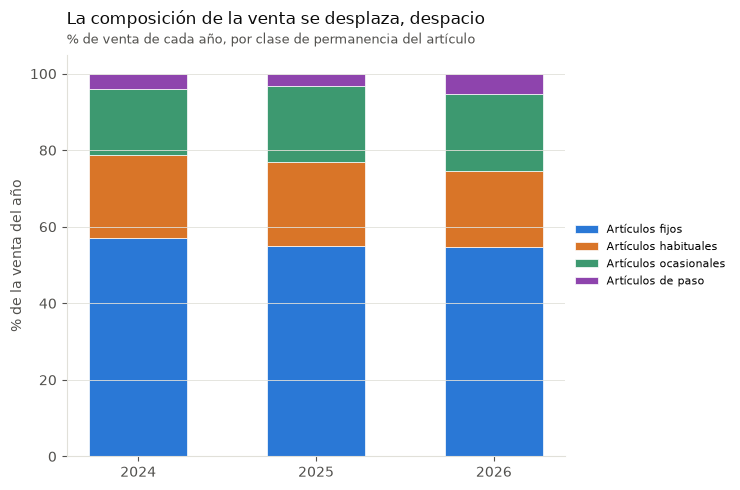

In [5]:
n_art = con_clase.pivot_table(index="clase", columns="año",
                              values="cod_articulo", aggfunc="nunique")
venta = con_clase.pivot_table(index="clase", columns="año",
                              values="total_venta", aggfunc="sum")
pct = 100 * venta / venta.sum()

tabla = pd.concat(
    {año: pd.DataFrame({"artículos": n_art[año].astype(int),
                         "% venta": pct[año].map(lambda v: num(v, 1))})
     for año in n_art.columns},
    axis=1)

print("El surtido de cada año: cuántos artículos y cuánto aportan\n")
print(tabla.to_string())

meses_2026 = sum(m.startswith(str(AÑOS[-1])) for m in MESES)

f, o = pct.loc[CLASES[0][2]], pct.loc[CLASES[2][2]]


# --- Gráfica: la composición de la venta se desplaza, despacio -------------
colores_clase = [AZUL, NARANJA, VERDE, MORADO]
años_str = [str(a) for a in n_art.columns]
x = np.arange(len(años_str))

fig, ax = plt.subplots(figsize=(7.5, 5))
abajo = np.zeros(len(años_str))
for (lo, hi, etiqueta), color in zip(CLASES, colores_clase):
    valores = pct.loc[etiqueta].values
    ax.bar(x, valores, bottom=abajo, width=0.55, color=color,
           edgecolor="white", linewidth=0.5,
           label=etiqueta.split(" · ")[1].split(" (")[0])
    abajo = abajo + valores
ax.set_xticks(x)
ax.set_xticklabels(años_str)
ax.set_ylabel("% de la venta del año")
ax.set_title("La composición de la venta se desplaza, despacio",
             color=TINTA, loc="left", pad=22)
ax.text(0, 1.02, "% de venta de cada año, por clase de permanencia del artículo",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "composicion-venta-por-clase-anual", VENTANA_COMPLETA)
plt.show()

2026 son 7 meses, no 12. Aparecen menos ocasionales y
de paso — han tenido menos tiempo de asomar. Los % de venta sí son
comparables entre años; los recuentos no.

Los artículos fijos ceden peso despacio: 57,0 % de la venta en 2024, 54,7 % en 2026. Lo que gana es
el surtido ocasional: 17,3 % → 20,2 %.
Deriva pequeña pero constante los tres años.

### 1.4 · Cuánto del surtido se mantiene de un año a otro

Lo anterior dice **cómo se reparte** el catálogo. Esto, **cuánto rota**.

Contar altas y bajas año a año no se puede: para saber que un artículo es
*nuevo* hay que ver que antes no estaba, y en enero de 2024 —el arranque de la
serie— todo *parece* nuevo. Así que se mira al revés: se toma el surtido del
último año y se separa lo que ya se vendía en 2024 de lo que no.


In [6]:
en_2024 = set(CATALOGO.loc[CATALOGO["año"] == AÑOS[0], "cod_articulo"])
cat_fin = CATALOGO[CATALOGO["año"] == AÑOS[-1]]
es_veterano = cat_fin["cod_articulo"].isin(en_2024)

n_fin = cat_fin["cod_articulo"].nunique()
vet_n = cat_fin.loc[es_veterano, "cod_articulo"].nunique()
vet_v = 100 * cat_fin.loc[es_veterano, "total_venta"].sum() / cat_fin["total_venta"].sum()


def fila(etiqueta, n, pct_venta):
    print(f"  {etiqueta:.<26} {num(n, 0):>6}  {num(100 * n / n_fin, 0):>3} %"
          f"   —  {num(pct_venta, 0):>2} % de la venta")


print(f"El surtido de {AÑOS[-1]} son {num(n_fin, 0)} artículos:")
fila(f"ya se vendían en {AÑOS[0]}", vet_n, vet_v)
fila(f"nuevos desde {AÑOS[0]}", n_fin - vet_n, 100 - vet_v)


meses_fin = sum(m.startswith(str(AÑOS[-1])) for m in MESES)

El surtido de 2026 son 4.362 artículos:
  ya se vendían en 2024.....  3.215   74 %   —  88 % de la venta
  nuevos desde 2024.........  1.147   26 %   —  12 % de la venta


Uno de cada cuatro artículos del lineal de 2026 es nuevo desde 2024, pero entre
todos hacen el 12 % de la venta. El catálogo se renueva por los bordes,
no por el centro.

2026 son 7 meses. El 26 % de nuevos es un techo:
un artículo que vende poco puede no haber asomado aún.

Con esto queda el **retrato de venta** del surtido. Para estudiar precio y
rentabilidad (apartado 4) hace falta un coste fiable, y eso reduce la base: el
apartado 2 estudia qué coste se usa y qué filas se quedan fuera, y el 3 fija la
base resultante.

## 2 · El coste: cómo se mide la rentabilidad y qué se deja fuera

El informe del TPV trae **tres** columnas de coste por artículo, y un `%Rent.`
distinto para cada una. Elegir es obligado, y hay que defender la elección.

### 2.1 · Las tres columnas

| | qué es |
|---|---|
| `costo_medio` | media móvil del coste sobre las existencias |
| `costo_ultimo` | coste de la última compra registrada |
| **`tarifa_costo`** | coste que consta en la **ficha** del artículo — la tarifa del proveedor |


In [7]:
# Cobertura sobre el catálogo entero, y margen sobre las filas limpias de cada
# columna (con esa columna, venta > 0, sin bolsas y sin coste disparatado por
# esa misma columna).
print("Cada columna de coste: cuánto cubre y qué margen da (31 meses)\n")
print(f"  {'columna':<14} {'cobertura filas':>16} {'cobertura venta':>16} {'margen (base limpia)':>22}")
for col in ["costo_medio", "costo_ultimo", "tarifa_costo"]:
    con = CATALOGO[CATALOGO[col] > 0]
    cob_f = 100 * len(con) / len(CATALOGO)
    cob_v = 100 * con["total_venta"].sum() / v_catalogo
    limpio_col = con[(con["total_venta"] > 0)
                     & (~con["cod_articulo"].isin(BOLSAS_CAJA))
                     & (~((con["precio"] > 0) & (con[col] > RATIO_COSTE_ABSURDO * con["precio"])))]
    mg = 100 * (limpio_col["total_venta"] - limpio_col["unidades"] * limpio_col[col]).sum() / limpio_col["total_venta"].sum()
    print(f"  {col:<14} {num(cob_f, 1) + ' %':>16} {num(cob_v, 1) + ' %':>16} "
          f"{num(mg, 2) + ' %':>22}")

# Coinciden `costo_ultimo` y `tarifa_costo`; el que va por libre es `costo_medio`.
tres = CATALOGO[(CATALOGO["costo_medio"] > 0) & (CATALOGO["costo_ultimo"] > 0)
                & (CATALOGO["tarifa_costo"] > 0)]
coinc_ut = (tres["tarifa_costo"].round(2) == tres["costo_ultimo"].round(2)).mean()
coinc_mu = (tres["costo_medio"].round(2) == tres["costo_ultimo"].round(2)).mean()

Cada columna de coste: cuánto cubre y qué margen da (31 meses)

  columna         cobertura filas  cobertura venta   margen (base limpia)
  costo_medio              91,9 %           89,4 %                39,08 %
  costo_ultimo             93,4 %           93,1 %                28,54 %
  tarifa_costo             99,7 %           99,9 %                28,36 %


`costo_medio` cubre menos (89 % de la venta frente al 99,9 % de `tarifa_costo`) Y da un margen 11 puntos más alto: infla.
Donde están las tres, `tarifa_costo` == `costo_ultimo` al céntimo en el 61,8 % de las filas; `costo_medio` coincide solo en el 28,5 %. Es el que se separa.

### 2.2 · El artículo testigo: el aceite de girasol

`costo_medio` no describe un coste. Para `400000 ACEITE GIRASOL COVIRAN 1` sube
un 2-3 % **cada mes durante dos años y no baja ni una vez**: es un acumulador
que deriva, no una compra real. La ficha que facilitó la tienda da **coste de
cesión 1,53 €, precio de venta 2,05 €**. `costo_ultimo` y `tarifa_costo` se
mueven entre 1,15 y 1,47 €, el orden de magnitud correcto.

Es la primera vez que una columna del programa se contrasta contra una fuente
externa. `costo_medio` queda descartado por contraste, no por sospecha.

In [8]:
COD_ACEITE = "400000"
ace = (CATALOGO[CATALOGO["cod_articulo"] == COD_ACEITE]
       .sort_values("periodo")[["periodo", "precio", "costo_medio", "costo_ultimo", "tarifa_costo"]])
print(f"`{COD_ACEITE} Aceite girasol coviran 1` — las tres columnas de coste, mes a mes:\n")
print(ace.to_string(index=False))

cm = ace["costo_medio"].replace(0, np.nan).dropna()
subidas = (cm.diff().dropna() > 0).mean()

`400000 Aceite girasol coviran 1` — las tres columnas de coste, mes a mes:

periodo  precio  costo_medio  costo_ultimo  tarifa_costo
2024-01    1,50         1,91          1,17          1,20
2024-02    1,32         1,96          1,17          1,17
2024-03    1,48         1,99          1,23          1,24
2024-04    1,29         2,04          1,15          1,13
2024-05    1,49         2,08          1,24          1,24
2024-06    1,43         2,11          1,22          1,22
2024-07    1,29         2,15          1,15          1,15
2024-08    1,37         2,18          1,20          1,22
2024-09    1,32         2,21          1,21          1,21
2024-10    1,36         2,25          1,21          1,21
2024-11    1,56         2,29          1,29          1,31
2024-12    1,62         2,32          1,33          1,36
2025-01    1,73         2,34          1,45          1,45
2025-02    1,71         2,37          1,45          1,45
2025-03    1,58         2,43          1,41          1,40
2025-04    1

`costo_medio` sube en el 100 % de los meses y llega a 3,13 €, un 105 % por
encima del coste de cesión real (1,53 €). `costo_ultimo` y `tarifa_costo` se quedan entre 1,13 y 1,47 €.
El aceite nunca se vendió con pérdidas: con `tarifa_costo` da un margen
del 8 % al 20 %, coherente con el «margen muy pequeño» que describe la
tienda.

### 2.3 · El retrato completo del artículo testigo

Seguir un solo artículo a lo largo de los 31 meses —demanda, precio y margen—
en vez de tratar el catálogo como un bloque. Se usa el mismo aceite de girasol
de arriba, que ya tiene detrás la historia de la columna de coste.

*`precio` es un promedio mensual ya redondeado, no el precio de un día suelto.*

  guardada 02-retrato-articulo-testigo-2024-01_2026-07.png / .svg


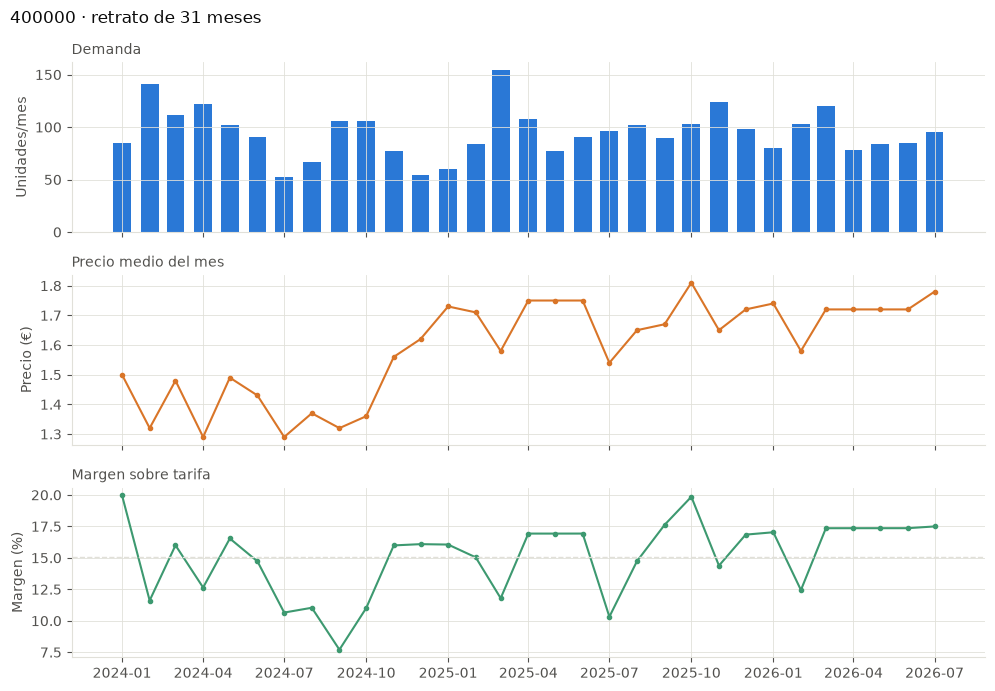

Precio: 1,29 → 1,81 € (media 1,59 €, CV 10,3 %)
Unidades: 52 → 154 (media 95,1, CV 24,2 %)
Margen: 7,7 % → 20,0 % (media 15,1 %, CV 19,8 %)


In [9]:
retrato = (CATALOGO[CATALOGO["cod_articulo"] == COD_ACEITE]
           .sort_values("periodo")
           .assign(margen_pct=lambda d: 100 * d["beneficio_tc"] / d["total_venta"]))
fechas = pd.to_datetime(retrato["periodo"])

fig, ejes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

ejes[0].bar(fechas, retrato["unidades"], color=AZUL, width=20)
ejes[0].set_ylabel("Unidades/mes")
ejes[0].set_title("Demanda", loc="left", fontsize=10, color=TINTA_SEC)

ejes[1].plot(fechas, retrato["precio"], color=NARANJA, marker="o", markersize=3)
ejes[1].set_ylabel("Precio (€)")
ejes[1].set_title("Precio medio del mes", loc="left", fontsize=10, color=TINTA_SEC)

ejes[2].plot(fechas, retrato["margen_pct"], color=VERDE, marker="o", markersize=3)
ejes[2].axhline(retrato["margen_pct"].mean(), color=GRID, linewidth=1, linestyle="--")
ejes[2].set_ylabel("Margen (%)")
ejes[2].set_title("Margen sobre tarifa", loc="left", fontsize=10, color=TINTA_SEC)

fig.suptitle(f"{COD_ACEITE} · retrato de 31 meses", x=0.01, ha="left",
            fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "retrato-articulo-testigo", VENTANA_COMPLETA)
plt.show()

corr_precio_tarifa = retrato["precio"].corr(retrato["tarifa_costo"])
corr_precio_unidades = retrato["precio"].corr(retrato["unidades"])
cv_precio = 100 * retrato["precio"].std() / retrato["precio"].mean()
cv_unidades = 100 * retrato["unidades"].std() / retrato["unidades"].mean()
cv_margen = 100 * retrato["margen_pct"].std() / retrato["margen_pct"].mean()

print(f"Precio: {num(retrato['precio'].min())} → {num(retrato['precio'].max())} € "
      f"(media {num(retrato['precio'].mean())} €, CV {num(cv_precio, 1)} %)")
print(f"Unidades: {num(retrato['unidades'].min(), 0)} → {num(retrato['unidades'].max(), 0)} "
      f"(media {num(retrato['unidades'].mean(), 1)}, CV {num(cv_unidades, 1)} %)")
print(f"Margen: {num(retrato['margen_pct'].min(), 1)} % → {num(retrato['margen_pct'].max(), 1)} % "
      f"(media {num(retrato['margen_pct'].mean(), 1)} %, CV {num(cv_margen, 1)} %)")

Precio y tarifa de coste se mueven casi a la vez (correlación 0,96): es lo que mantiene el margen dentro de una banda
razonable pese a que las dos series suben. La demanda es más ruidosa que
el precio (CV 24,2 % frente a 10,3 %), y su
correlación con el precio es débil (-0,15):
con un solo artículo y series mensuales no se puede leer elasticidad,
solo describir el patrón mes a mes.

### 2.4 · Qué se excluye de la base de margen

Además de fijar la columna, hay filas que no admiten un cálculo de margen y se
quedan fuera. Cada una con su motivo y su peso:

In [10]:
roto = (CATALOGO["precio"] > 0) & (CATALOGO[BASE_COSTE] > RATIO_COSTE_ABSURDO * CATALOGO["precio"])
sin_coste = CATALOGO[BASE_COSTE] <= 0
sin_venta = CATALOGO["total_venta"] <= 0
es_bolsa = CATALOGO["cod_articulo"].isin(BOLSAS_CAJA)


def resume(mascara, etiqueta):
    g = CATALOGO[mascara]
    print(f"  {etiqueta:<52} {num(len(g), 0):>6} filas   "
          f"{num(g['total_venta'].sum()):>12} €")


es_frio = CATALOGO["cod_articulo"].isin(FRIOS_TODOS)

print("Filas que no entran en la base de margen\n")
resume(sin_coste, "sin `tarifa_costo`")
resume(roto, f"coste > {RATIO_COSTE_ABSURDO}× el precio")
resume(sin_venta, "venta ≤ 0 (producto sin cobrar o devolución neta)")
resume(es_bolsa, "las dos bolsas de caja — cuentan como venta, no como surtido")
resume(es_frio, "los 9 códigos de bebida fría — su margen se mide aparte, §7")
print("  (una fila puede caer en más de una categoría: no se suman)")

# El efecto de la fila residual sobre 2024: es la diferencia entre un capítulo
# verdadero y uno falso.
b24 = CATALOGO[(CATALOGO["año"] == 2024) & (CATALOGO[BASE_COSTE] > 0) & (~sin_venta)]
print(f"\n  El coste disparatado de las bolsas, si no se excluye, hunde el margen de")
print(f"  2024 a {num(margen_ponderado(b24), 1)} % en vez del "
      f"{num(margen_ponderado(b24[~b24['cod_articulo'].isin(BOLSAS_CAJA) & ~((b24['precio'] > 0) & (b24[BASE_COSTE] > RATIO_COSTE_ABSURDO * b24['precio']))]), 1)} % real. "
      f"Diez filas de {num(len(CATALOGO), 0)} daban la vuelta a un capítulo.")


Filas que no entran en la base de margen

  sin `tarifa_costo`                                      260 filas       2.675,36 €
  coste > 10× el precio                                    22 filas       1.504,66 €
  venta ≤ 0 (producto sin cobrar o devolución neta)        81 filas        -106,02 €
  las dos bolsas de caja — cuentan como venta, no como surtido     62 filas       7.508,79 €
  los 9 códigos de bebida fría — su margen se mide aparte, §7    239 filas      16.869,28 €
  (una fila puede caer en más de una categoría: no se suman)

  El coste disparatado de las bolsas, si no se excluye, hunde el margen de
  2024 a 26,7 % en vez del 27,6 % real. Diez filas de 91.731 daban la vuelta a un capítulo.


### 2.5 · Los artículos que el informe da bajo coste

El informe marca **391 filas artículo×mes** vendidas por debajo de coste. La
tienda sostiene que no vende bajo coste como política y que actualiza el precio
el mismo día en que le sube el coste, así que los **258** artículos implicados
se auditan uno a uno. La clasificación la hace
[`src/clasificar_bajo_coste.py`](../src/clasificar_bajo_coste.py).

In [11]:
import clasificar_bajo_coste as cbc

bc = cbc.clasificar()                       # una fila por artículo×mes en pérdida
bc["cod_articulo"] = bc["cod_articulo"].astype(str)
art_bc = cbc.por_articulo(bc)              # una fila por artículo (causa = su peor mes)

# La tabla por causa se cuenta por artículo (cada artículo entero en la causa
# de su mes de mayor pérdida), que es como sale en la memoria y en el CSV.
resumen_bc = (art_bc.groupby("causa")
               .agg(artículos=("descripcion", "size"), filas=("meses_en_perdida", "sum"),
                    venta=("venta", "sum"), pérdida=("perdida", "sum")))
resumen_bc["% pérdida"] = 100 * resumen_bc["pérdida"] / art_bc["perdida"].sum()
orden_causa = ["pack_unidad", "coste_ficha", "promocion", "sin_firma"]
print("Los 258 artículos bajo coste, por causa (por artículo, como en la memoria)\n")
print(resumen_bc.reindex(orden_causa).round(2).to_string())

v_bc = bc["total_venta"].sum()
print(f"\n  En total: {num(len(art_bc), 0)} artículos, {num(len(bc), 0)} filas "
      f"artículo×mes, {num(v_bc)} € de venta ({num(100 * v_bc / v_catalogo, 2)} % del "
      f"catálogo), {num(bc['beneficio_tc'].sum())} € de pérdida.")

defec = bc[bc["causa"].isin(cbc.DEFECTOS_DE_COSTE)]
art_defec = art_bc[art_bc["causa"].isin(cbc.DEFECTOS_DE_COSTE)]
print(f"\nEl {num(100 * art_defec['perdida'].sum() / art_bc['perdida'].sum(), 1)} % "
      f"de la pérdida son dos defectos de la columna de coste, no ventas:")
print("   · `pack_unidad`  — el coste de la caja o del pack cruzado con el precio")
print("     de la unidad o del kilo. Es la fila residual otra vez, por debajo de su umbral de")
print("     10×. Aquí cae la magdalena de aceite de oliva a granel (54933): caja de")
print("     2 kg contra venta al kilo, confirmado por la tienda; el §3 le corrige la")
print("     tarifa en vez de excluirla.")
print("   · `coste_ficha`  — episodios sueltos de uno o dos meses en los que")
print("     `costo_medio` queda por debajo del precio: la venta fue rentable contra")
print("     `costo_medio` y solo la tarifa dice lo contrario. Ninguno sostiene un")
print("     patrón por sí solo; se cuentan como bloque.")
print("   Lo demás son promociones que la tienda sí declaró (liquidación) y un")
print("   residuo de céntimos repartido en artículos sueltos.")


Los 258 artículos bajo coste, por causa (por artículo, como en la memoria)

             artículos  filas    venta  pérdida  % pérdida
causa                                                     
pack_unidad          3     36 3.077,98  -415,78      49,63
coste_ficha         94    155 1.575,33  -172,51      20,59
promocion           78     97   982,06  -108,46      12,95
sin_firma           83    103   684,50  -140,99      16,83

  En total: 258 artículos, 391 filas artículo×mes, 6.319,87 € de venta (0,31 % del catálogo), -837,74 € de pérdida.

El 70,2 % de la pérdida son dos defectos de la columna de coste, no ventas:
   · `pack_unidad`  — el coste de la caja o del pack cruzado con el precio
     de la unidad o del kilo. Es la fila residual otra vez, por debajo de su umbral de
     10×. Aquí cae la magdalena de aceite de oliva a granel (54933): caja de
     2 kg contra venta al kilo, confirmado por la tienda; el §3 le corrige la
     tarifa en vez de excluirla.
   · `coste_ficha`  — epis

In [12]:
# Testigos del defecto grande: pack_unidad.
print("--- `pack_unidad`: coste de la caja o del pack contra precio de la unidad o del kilo ---")
mag = bc[bc["cod_articulo"] == "54933"]
if len(mag):
    print(f"  54933 Magdalena aceite oliva — pierde en {mag['periodo'].nunique()} meses, "
          f"{num(mag['beneficio_tc'].sum())} €, Exactamente -10,00 % todos los meses.")
    print(f"  La tarifa (6,35 €) es la caja de 2 KG; la magdalena se vende a granel al")
    print(f"  kilo, así que el informe cruza el precio del kilo con el coste de la caja.")
    print(f"  La tienda lo confirma (2026-09-09): tarifa ÷ 2 da un margen del 45 %. El §3 aplica")
    print(f"  esa corrección y el artículo vuelve al surtido en vez de excluirse.")

agua = bc[bc["cod_articulo"] == "35061"]
if len(agua):
    print(f"\n  35061 Agua con gas fonter 50 — suelto a 0,72 €, pack de seis a 4,13 €")
    print(f"  (= 0,69 €/botella). En 2026-07 el informe cruzó el precio de la botella")
    print(f"  con el coste del pack: {num(agua['beneficio_tc'].sum())} € de pérdida. A este")
    print(f"  lo caza el clasificador solo, por el salto de coste frente a sus meses sanos.")

# Fuerza de la prueba de los dos defectos.
print("\n--- Con qué fuerza está demostrado cada tramo ---")
fz = cbc.fuerza_de_la_prueba(bc)
print(fz.round(2).to_string())

# Claves (código, periodo) de las filas-error, para excluirlas del surtido.
defec_excl = defec[~defec["cod_articulo"].isin(cbc.CAJA_A_GRANEL)]
CLAVES_ERROR_BC = set(zip(defec_excl["cod_articulo"], defec_excl["periodo"]))
n_corr = len(bc[bc["cod_articulo"].isin(cbc.CAJA_A_GRANEL)])
print(f"\n{len(CLAVES_ERROR_BC)} filas artículo×mes se excluyen del surtido; "
      f"{n_corr} más (caja→granel) se corrigen en el §3.")

--- `pack_unidad`: coste de la caja o del pack contra precio de la unidad o del kilo ---
  54933 Magdalena aceite oliva — pierde en 30 meses, -289,92 €, Exactamente -10,00 % todos los meses.
  La tarifa (6,35 €) es la caja de 2 KG; la magdalena se vende a granel al
  kilo, así que el informe cruza el precio del kilo con el coste de la caja.
  La tienda lo confirma (2026-09-09): tarifa ÷ 2 da un margen del 45 %. El §3 aplica
  esa corrección y el artículo vuelve al surtido en vez de excluirse.

  35061 Agua con gas fonter 50 — suelto a 0,72 €, pack de seis a 4,13 €
  (= 0,69 €/botella). En 2026-07 el informe cruzó el precio de la botella
  con el coste del pack: -14,78 € de pérdida. A este
  lo caza el clasificador solo, por el salto de coste frente a sus meses sanos.

--- Con qué fuerza está demostrado cada tramo ---
            filas  perdida   pct
nivel                           
solido         50  -422,14 71,44
intermedio     14    -3,18  0,54
flojo         123  -165,56 28,02

157 f

La mitad larga está demostrada artículo por artículo; algo más de un tercio
que se apoya en un indicio único solo se defiende como patrón agregado,
y así se declara en la memoria.

## 3 · La base de rentabilidad: `SURTIDO`

Aquí se fija, una sola vez, la base sobre la que van **todas** las cifras de
precio y margen del resto del notebook: el catálogo menos las bolsas de caja,
los 9 códigos de bebida fría (apartado 7), las filas sin `tarifa_costo`, las de
coste disparatado, las de venta cero y las que el apartado 2.5 marcó como error
de coste. Hay una excepción: a los artículos que la tienda confirma comprados
por caja y vendidos a granel se les **corrige** la tarifa en vez de excluirlos.

In [13]:
clave = list(zip(CATALOGO["cod_articulo"].astype(str), CATALOGO["periodo"]))
es_error = pd.Series([k in CLAVES_ERROR_BC for k in clave], index=CATALOGO.index)
if not EXCLUIR_ERRORES_BC:
    es_error = pd.Series(False, index=CATALOGO.index)

# Corrección de coste por error de unidad (caja→granel) en los artículos que la
# tienda confirma.
CATALOGO_COR = cbc.corregir_caja_a_granel(CATALOGO)

# La base tal como estaba antes de la exclusión de los artículos bajo coste (para medir su efecto).
SURTIDO_SIN_BC = CATALOGO_COR[~roto & ~sin_coste & ~sin_venta & ~es_bolsa & ~es_frio].copy()
SURTIDO = SURTIDO_SIN_BC[~es_error.loc[SURTIDO_SIN_BC.index]].copy()
SURTIDO["coste"] = SURTIDO["unidades"] * SURTIDO[BASE_COSTE]

cobertura = 100 * SURTIDO["total_venta"].sum() / v_catalogo
cobertura_sin_bc = 100 * SURTIDO_SIN_BC["total_venta"].sum() / v_catalogo
COD_FIJOS = set(meses_vivo[meses_vivo == len(MESES)].index)
AÑO_MOVIL = SURTIDO[SURTIDO["periodo"].isin(MESES_RECIENTES)].copy()

print(f"SURTIDO : {num(len(SURTIDO), 0)} filas artículo×mes, "
      f"{num(SURTIDO['cod_articulo'].nunique(), 0)} artículos distintos")
print(f"          {num(SURTIDO['total_venta'].sum())} € — el {num(cobertura, 2)} % "
      f"de la venta del catálogo")
print(f"          {num(len(SURTIDO_SIN_BC) - len(SURTIDO), 0)} filas menos que la "
      f"base sin excluir los artículos bajo coste (cobertura {num(cobertura_sin_bc, 2)} %)")

SURTIDO : 91.063 filas artículo×mes, 6.647 artículos distintos
          2.020.111,83 € — el 98,70 % de la venta del catálogo
          157 filas menos que la base sin excluir los artículos bajo coste (cobertura 98,78 %)


Toda cifra de margen de aquí en adelante va sobre ese 98,70 %,
y hay que citarlo cada vez.

## 4 · Rentabilidad del surtido

Todo sobre `SURTIDO`, con el margen **ponderado por venta**: el margen en euros
de un grupo dividido entre su venta, de modo que un artículo que vende mucho
pesa mucho.

### 4.1 · El margen global, y su evolución

In [14]:
mg_global = margen_ponderado(SURTIDO)
anual = (SURTIDO.groupby("año")
         .apply(lambda g: pd.Series({
             "artículos": g["cod_articulo"].nunique(),
             "venta (€)": g["total_venta"].sum(),
             "margen (%)": margen_ponderado(g),
         }), include_groups=False))
anual["artículos"] = anual["artículos"].astype(int)
print(f"Margen global del SURTIDO — periodo completo (31 meses) : {num(mg_global, 2)} %")
print(f"  cobertura: el {num(cobertura, 2)} % de la venta del catálogo\n")
print(anual.round(2).to_string())

m0, m1 = anual["margen (%)"].iloc[0], anual["margen (%)"].iloc[-1]

Margen global del SURTIDO — periodo completo (31 meses) : 28,38 %
  cobertura: el 98,70 % de la venta del catálogo

      artículos  venta (€)  margen (%)
año                                   
2024       4938 753.795,10       27,61
2025       5062 801.412,41       28,50
2026       4337 464.904,32       29,39


El margen no está plano: sube de 27,61 % en 2024 a 29,39 % en 2026, casi dos puntos en tres años, sin que la
cesta haya cambiado apenas (§1.3). Es gestión de precio y de compra.

### 4.2 · Los más y los menos rentables

**Sobre los artículos fijos: los que están los 31 meses.** Es la única población
con observaciones suficientes para ordenarla por margen sin que el ranking sea
ruido. Se les pide además coste utilizable en 24 de esos 31 meses o más —el
filtro descarta 7 de los 856 y ninguno pesa— para que ningún margen salga de
tres o cuatro datos. Un 97 % sobre 10 € de venta no es un hallazgo; un −40 %
sobre 4.000 € sí, así que los euros van al lado del porcentaje.


Artículos fijos (los 31 meses): 856. Con coste utilizable en 24+ de esos meses: 849 — el ranking va sobre esos.

Los 12 más rentables
              artículo  meses     venta  margen (€)  margen (%)
               PUERROS     31  1.573,40      949,69       60,36
           REPOLLO-COL     31    606,89      345,38       56,91
 CARNE PICADA CERDO KG     31 13.246,94    7.393,22       55,81
      ARREGLO TRASEROS     31  1.633,46      911,32       55,79
       CALABAZA VIOLIN     31  1.024,55      549,74       53,66
         FABIOLA PICOS     31  1.135,38      575,60       50,70
   CEBOLLA ROJA GRANEL     31    379,92      189,19       49,80
 CEBOLLAS GRANEL 10 KG     31  2.792,03    1.384,01       49,57
     FILM COVIRAN 30 M     31    171,46       82,54       48,14
   ZANAHORIA GRANEL KG     31    752,98      358,72       47,64
    PATATA ROJA GRANEL     31  5.859,62    2.627,47       44,84
MAGDALENA ACEITE OLIVA     31  2.949,24    1.312,56       44,50

Los 12 menos rentables
          

  guardada 02-ranking-rentabilidad-fijos-2024-01_2026-07.png / .svg


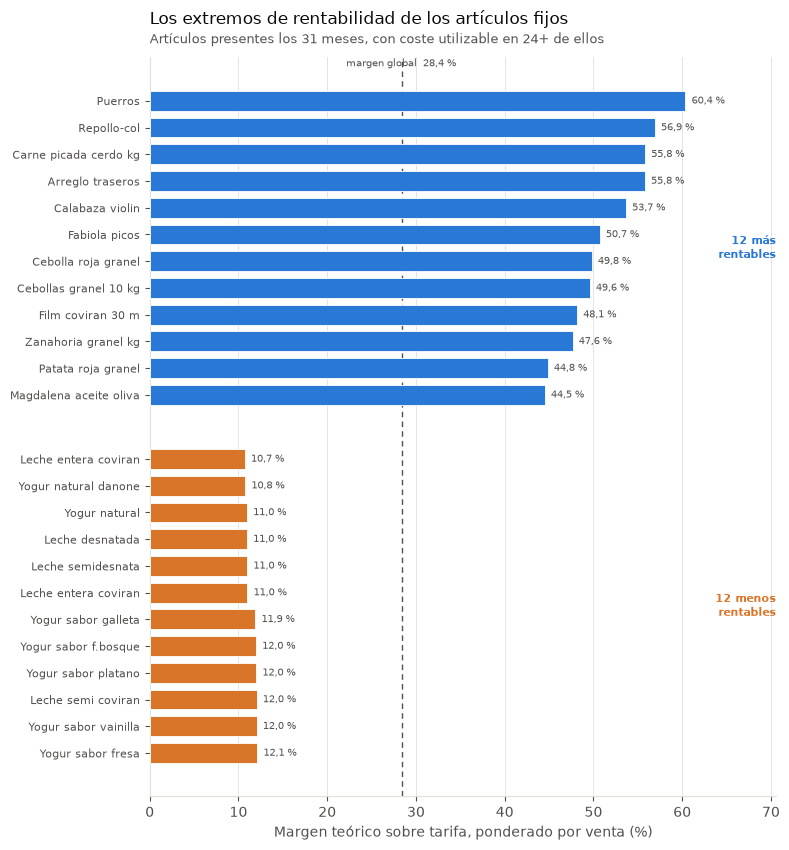

In [15]:
MIN_MESES_COSTE = 24

fij = SURTIDO[SURTIDO["cod_articulo"].isin(COD_FIJOS)]
meses_coste = fij.groupby("cod_articulo")["periodo"].nunique()
solidos = meses_coste[meses_coste >= MIN_MESES_COSTE].index

nombre = (fij.assign(limpio=fij["descripcion"].str.strip()
                     .str.replace(r"^\((P|FID|REG)\)", "", regex=True)
                     .str.replace(r"\s+", " ", regex=True))
          .groupby("cod_articulo")["limpio"].agg(lambda s: s.mode().iloc[0]))

rank = (fij[fij["cod_articulo"].isin(solidos)]
        .groupby("cod_articulo")
        .agg(meses=("periodo", "nunique"), venta=("total_venta", "sum"),
             margen_euros=("beneficio_tc", "sum")))
rank["margen (%)"] = 100 * rank["margen_euros"] / rank["venta"]
rank = rank.rename(columns={"margen_euros": "margen (€)"})
rank.insert(0, "artículo", nombre.reindex(rank.index))

print(f"Artículos fijos (los 31 meses): {num(len(COD_FIJOS), 0)}. Con coste "
      f"utilizable en {MIN_MESES_COSTE}+ de esos meses: {num(len(solidos), 0)} — "
      f"el ranking va sobre esos.\n")
cols = ["artículo", "meses", "venta", "margen (€)", "margen (%)"]
print("Los 12 más rentables")
print(rank.nlargest(12, "margen (%)")[cols].to_string(index=False))
print("\nLos 12 menos rentables")
print(rank.nsmallest(12, "margen (%)")[cols].to_string(index=False))

bajo = rank[rank["margen (%)"] < 0]
peor = rank.nsmallest(1, "margen (%)").iloc[0]


# --- Gráfica: los extremos de rentabilidad --------------------------------
top = rank.nlargest(12, "margen (%)").sort_values("margen (%)")
bot = rank.nsmallest(12, "margen (%)").sort_values("margen (%)", ascending=False)
comb = pd.concat([bot, top])

GAP = 1.4                                   # hueco entre los dos bloques
ys = np.concatenate([np.arange(len(bot)),
                     np.arange(len(top)) + len(bot) + GAP])
colores = [NARANJA] * len(bot) + [AZUL] * len(top)

fig, ax = plt.subplots(figsize=(8, 8.6))
barras = ax.barh(ys, comb["margen (%)"], height=0.74, color=colores,
                 edgecolor="white", linewidth=0.6, zorder=3)

# el valor al final de cada barra: se lee sin ir al eje
for rect, v in zip(barras, comb["margen (%)"]):
    ax.text(rect.get_width() + 0.7, rect.get_y() + rect.get_height() / 2,
            f"{num(v, 1)} %", va="center", ha="left", fontsize=7.5, color=TINTA_SEC)

# el margen global del surtido, como vara de medir
ax.axvline(mg_global, color=TINTA_SEC, lw=1, ls=(0, (4, 3)), zorder=2)
ax.text(mg_global, ys.max() + 1.2, f"margen global  {num(mg_global, 1)} %",
        ha="center", va="bottom", fontsize=7.5, color=TINTA_SEC)

# rótulo de cada bloque, a la derecha
xr = comb["margen (%)"].max() * 1.17
ax.text(xr, np.median(ys[len(bot):]), "12 más\nrentables", ha="right", va="center",
        fontsize=8, color=AZUL, weight="bold")
ax.text(xr, np.median(ys[:len(bot)]), "12 menos\nrentables", ha="right", va="center",
        fontsize=8, color=NARANJA, weight="bold")

ax.set_yticks(ys)
ax.set_yticklabels([a.strip().capitalize() for a in comb["artículo"]], fontsize=8)
ax.set_xlim(0, xr)
ax.set_xlabel("Margen teórico sobre tarifa, ponderado por venta (%)")
ax.set_title("Los extremos de rentabilidad de los artículos fijos",
             color=TINTA, loc="left", pad=24)
ax.text(0, 1.015, f"Artículos presentes los {len(MESES)} meses, con coste utilizable "
        f"en {MIN_MESES_COSTE}+ de ellos", transform=ax.transAxes,
        color=TINTA_SEC, fontsize=9, va="bottom")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", zorder=0)
fig.tight_layout()
guardar(fig, "ranking-rentabilidad-fijos", VENTANA_COMPLETA)
plt.show()

Ningún artículo fijo queda con margen negativo sostenido (0 de 849). El más flojo es «leche entera Covirán», al 10,7 %.
Es un resultado en sí: lo que `costo_medio` daba como fijos en pérdida
—aceites de girasol, sobre todo— era artefacto de esa columna,
no venta bajo coste.

Los 12 menos rentables son leche y yogur, al 10-12 %: margen bajo pero
positivo, coherente con productos de tráfico —el cliente entra a por la
leche—. En el otro extremo, hortaliza a granel, por encima del 45 %.

### 4.3 · Margen por departamento

Sobre el **año móvil** (últimos 12 meses): así el margen describe la tienda de
hoy y no mezcla 2024 con 2026.

**Se pondera por venta.** La alternativa habitual, la media aritmética de los
porcentajes, da el mismo peso a un artículo que vende 3 € que a otro que vende
3.000 €. Con la base limpia la diferencia entre las dos es pequeña, pero
ponderar sigue siendo lo correcto.

En la figura hay **una barra por departamento con su margen ponderado** y una
línea con el margen de toda la tienda en el mismo año móvil. La media simple
queda en la tabla.

Margen por departamento — año móvil

                              filas      venta  media simple (%)  ponderada (%)  sd (pp)  % en pérdida  sesgo (pp)
departamento                                                                                                      
ULTRAMARINOS                  16516 270.111,10             27,46          25,51     7,14          0,21        1,94
CARNICERIA                      945 107.715,20             34,72          35,17     7,14          0,00       -0,45
BEBIDAS                        3812  97.524,40             27,48          26,41     7,47          0,08        1,07
FRUTAS Y VERDURAS              1429  83.014,39             36,61          37,05    13,00          0,70       -0,44
DROGUERIA Y PERFUMERIA         6664  63.648,71             29,89          29,31     6,85          0,23        0,58
PANADERIA PASTELERIA            475  62.352,42             33,40          36,91     6,33          0,00       -3,50
CONGELADOS                     1542  38.434

  guardada 02-rentabilidad-departamento-2025-08_2026-07.png / .svg


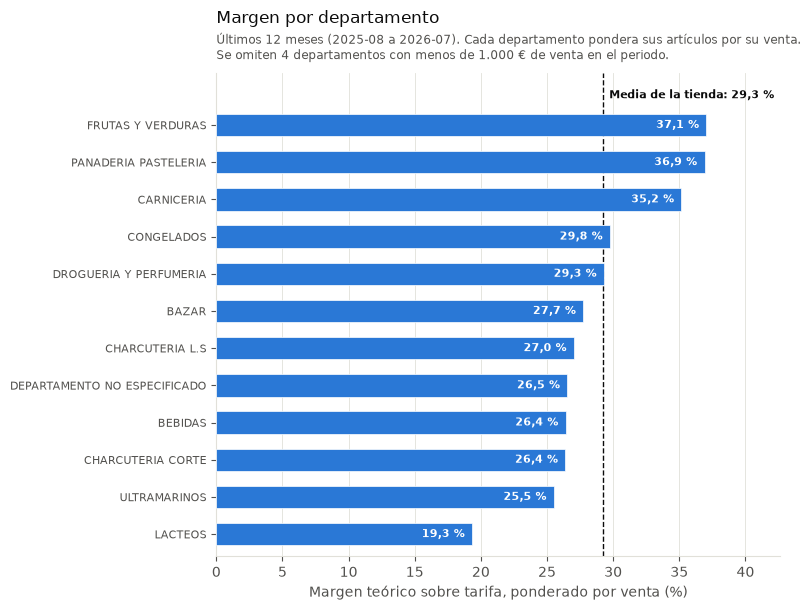

In [16]:
comp = (AÑO_MOVIL.groupby("departamento")
        .apply(lambda g: pd.Series({
            "filas": len(g),
            "venta": g["total_venta"].sum(),
            "media simple (%)": g["pct_rent_tc"].mean(),
            "ponderada (%)": margen_ponderado(g),
            "sd (pp)": g["pct_rent_tc"].std(),
            "% en pérdida": 100 * (g["beneficio_tc"] < 0).mean(),
        }), include_groups=False)
        .sort_values("venta", ascending=False))
comp["sesgo (pp)"] = comp["media simple (%)"] - comp["ponderada (%)"]
comp["filas"] = comp["filas"].astype(int)
print("Margen por departamento — año móvil\n")
print(comp.round(2).to_string())

g_pond = margen_ponderado(AÑO_MOVIL)
print(f"\nGlobal año móvil: ponderada {num(g_pond, 2)} %  |  "
      f"media simple {num(AÑO_MOVIL['pct_rent_tc'].mean(), 2)} %  "
      f"(sesgo {num(AÑO_MOVIL['pct_rent_tc'].mean() - g_pond, 2, signo=True)} pp)")


# --- Gráfica: margen por departamento (ponderado), con la media de la tienda ---
# Una barra por departamento con el margen ponderado y una línea con el margen
# de toda la tienda en el mismo año móvil, que es con lo que el texto de la
# memoria compara.
omitidos = comp[comp["venta"] < VENTA_MIN_DPTO_FIGURA]
c = comp[comp["venta"] >= VENTA_MIN_DPTO_FIGURA].sort_values("ponderada (%)")
print(f"\nFuera de la figura, por vender menos de {num(VENTA_MIN_DPTO_FIGURA, 0)} € "
      f"en el año móvil: {len(omitidos)} departamentos")
print(omitidos[["filas", "venta"]].round(2).to_string())
y = np.arange(len(c))
xmax = c["ponderada (%)"].max()

fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(y, c["ponderada (%)"], height=0.60, color=AZUL, edgecolor="white",
        linewidth=0.5, zorder=3)
for yi, pond in enumerate(c["ponderada (%)"]):
    ax.text(pond - xmax * 0.015, yi, f"{num(pond, 1)} %", va="center", ha="right",
            fontsize=8, color="white", weight="bold")

ax.axvline(g_pond, color=TINTA, linestyle="--", linewidth=1, zorder=2)
ax.text(g_pond + xmax * 0.012, len(c) - 0.35, f"Media de la tienda: {num(g_pond, 1)} %",
        va="bottom", ha="left", fontsize=8, color=TINTA, weight="bold")

ax.set_yticks(y)
ax.set_yticklabels(c.index, fontsize=8)
ax.set_xlim(0, xmax * 1.15)
ax.set_ylim(-0.6, len(c) + 0.4)
ax.set_xlabel("Margen teórico sobre tarifa, ponderado por venta (%)")
ax.set_title("Margen por departamento", color=TINTA, loc="left", pad=36)
ax.text(0, 1.02, f"Últimos {MESES_AÑO_MOVIL} meses ({MESES_RECIENTES[0]} a "
        f"{MESES_RECIENTES[-1]}). Cada departamento pondera sus artículos por su venta.\n"
        f"Se omiten {len(omitidos)} departamentos con menos de "
        f"{num(VENTA_MIN_DPTO_FIGURA, 0)} € de venta en el periodo.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=8.5, va="bottom")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", zorder=0)
fig.tight_layout()
guardar(fig, "rentabilidad-departamento", VENTANA_AÑO_MOVIL)
plt.show()

La dispersión interna (sd) separa un departamento con precios variados
de uno con artículos en pérdida: la columna «% en pérdida» lo desambigua.

### 4.4 · ¿Rinde igual lo que se queda que lo que rota?

El apartado 1.3 mostró que los fijos ceden peso al surtido ocasional. Esa deriva
**solo es inocua si las dos clases rinden igual**, y no rinden igual.

Margen ponderado por clase de permanencia

                                          venta (€)  margen (%)
clase                                                          
1 · Artículos fijos (los 31 meses)     1.119.475,40       28,76
2 · Artículos habituales (24-30 meses)   433.521,18       27,77
3 · Artículos ocasionales (7-23 meses)   385.288,40       28,11
4 · Artículos de paso (1-6 meses)         81.826,85       27,55

Y año a año:
año                                     2024  2025  2026
clase                                                   
1 · Artículos fijos (los 31 meses)     27,80 28,98 30,00
2 · Artículos habituales (24-30 meses) 27,14 27,82 28,80
3 · Artículos ocasionales (7-23 meses) 27,69 28,15 28,63
4 · Artículos de paso (1-6 meses)      27,22 27,25 28,26


  guardada 02-margen-por-clase-evolucion-2024-01_2026-07.png / .svg


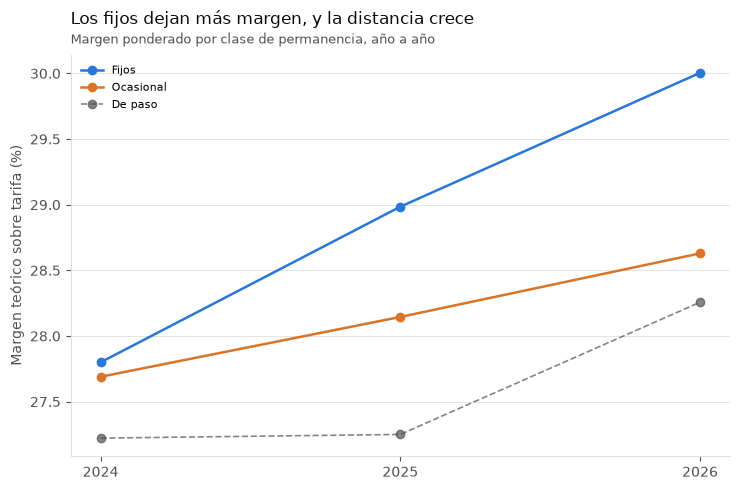

In [17]:
margen_clase = (SURTIDO.assign(clase=SURTIDO["cod_articulo"].map(clase))
                .groupby("clase")
                .apply(lambda g: pd.Series({
                    "venta (€)": g["total_venta"].sum(),
                    "margen (%)": margen_ponderado(g),
                }), include_groups=False))
por_año_clase = (SURTIDO.assign(clase=SURTIDO["cod_articulo"].map(clase))
                  .groupby(["clase", "año"])
                  .apply(margen_ponderado, include_groups=False)
                  .unstack())

print("Margen ponderado por clase de permanencia\n")
print(margen_clase.round(2).to_string())
print("\nY año a año:")
print(por_año_clase.round(2).to_string())

fijo, ocas, paso = CLASES[0][2], CLASES[2][2], CLASES[3][2]
brecha = margen_clase.loc[fijo, "margen (%)"] - margen_clase.loc[paso, "margen (%)"]


# --- Gráfica: los fijos dejan más margen, y la brecha crece ---------------
# Las tres clases suben; lo que se ve es que los fijos dejan más margen
# todos los años y que la distancia crece.
fig, ax = plt.subplots(figsize=(7.5, 5))
cols_año = por_año_clase.columns
ax.plot(cols_año, por_año_clase.loc[fijo], color=AZUL, marker="o", lw=1.8, label="Fijos")
ax.plot(cols_año, por_año_clase.loc[ocas], color=NARANJA, marker="o", lw=1.8, label="Ocasional")
ax.plot(cols_año, por_año_clase.loc[paso], color=TINTA_SEC, marker="o", lw=1.2,
        ls="--", alpha=0.7, label="De paso")
ax.set_ylabel("Margen teórico sobre tarifa (%)")
ax.set_xticks(cols_año)
ax.set_title("Los fijos dejan más margen, y la distancia crece",
             color=TINTA, loc="left", pad=22)
ax.text(0, 1.02, "Margen ponderado por clase de permanencia, año a año",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "margen-por-clase-evolucion", VENTANA_COMPLETA)
plt.show()

El margen baja según cae la permanencia: del 28,8 % de los fijos al 27,5 % de lo de paso (1,2 pp de brecha). Lo que rota no solo vende poco: vende peor.
La deriva de §1.3 arrastra el agregado hacia abajo —unas décimas con el
desplazamiento medido— pero la dirección importa si continúa.

### 4.5 · Distribución de precios por departamento

Sobre el año móvil. **Escala logarítmica**: conviven artículos de céntimos con
otros de decenas de euros, y en escala lineal la dispersión aplasta todas las
cajas contra el cero.

> `precio` es un **promedio del mes redondeado a dos decimales**, no el precio
> de un día. Sirve para comparar órdenes de magnitud entre departamentos, no
> para fijar precios.

  guardada 02-precios-por-departamento-2025-08_2026-07.png / .svg


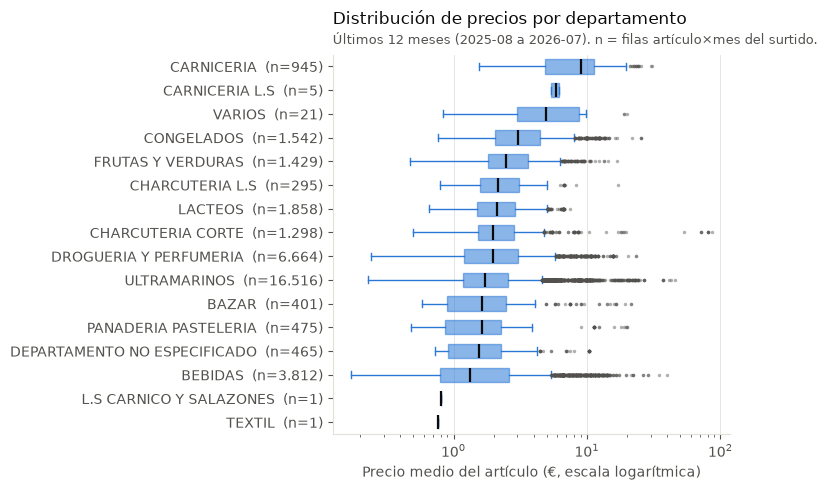

In [18]:
orden = AÑO_MOVIL.groupby("departamento")["precio"].median().sort_values().index.tolist()
datos = [AÑO_MOVIL.loc[AÑO_MOVIL["departamento"] == d, "precio"].dropna().values for d in orden]
etiquetas = [f"{d}  (n={len(x):,})".replace(",", ".") for d, x in zip(orden, datos)]

fig, ax = plt.subplots(figsize=(7.5, 5))
bp = ax.boxplot(datos, orientation="horizontal", tick_labels=etiquetas,
                patch_artist=True, widths=0.6,
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=TINTA_SEC,
                                markeredgecolor="none", alpha=0.45))
for caja in bp["boxes"]:
    caja.set(facecolor=AZUL, alpha=0.55, edgecolor=AZUL, linewidth=1)
for elem in ("whiskers", "caps"):
    for linea in bp[elem]:
        linea.set(color=AZUL, linewidth=1)
for mediana in bp["medians"]:
    mediana.set(color=TINTA, linewidth=1.6)
ax.set_xscale("log")
ax.set_xlabel("Precio medio del artículo (€, escala logarítmica)")
ax.set_title("Distribución de precios por departamento",
             color=TINTA, loc="left", pad=22)
ax.text(0, 1.02, f"Últimos {MESES_AÑO_MOVIL} meses ({MESES_RECIENTES[0]} a {MESES_RECIENTES[-1]}). "
        "n = filas artículo×mes del surtido.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "precios-por-departamento", VENTANA_AÑO_MOVIL)
plt.show()

med = AÑO_MOVIL.groupby("departamento")["precio"].median().sort_values()

Mediana de precio de 0,77 € (textil) a 9,03 € (carniceria).

## 5 · ¿El 30 % de los ingresos viene de frescos?

Las gerentes dieron una referencia del sector: *lo ideal en una tienda como
esta es que en torno al 30 % de los ingresos vengan de producto fresco*. Se
comprueba.

**Se calcula sobre la venta total del diario por artículo**, no sobre
`SURTIDO`: el genérico `82557 CARNICERIA` —carne al peso vendida contra un
código sin ficha, el 4,5 % de la venta— es venta fresca aunque no entre en el
análisis de margen.

**«Fresco» es una definición propia y declarada:** carnicería, charcutería,
frutas y verduras, panadería y pastelería, y pescado. Los lácteos y las
variantes dudosas se prueban en la tabla de sensibilidad.

Peso del producto fresco sobre los ingresos

  2024 : 38,4 %
  2025 : 38,8 %
  2026 : 38,9 %
  ---
  31 meses : 38,7 %      referencia del sector: 30 %

Sensibilidad a la definición (31 meses)

  núcleo (carnicería + charcutería + frutas + panadería + pescado) 38,7 %
  + lácteos                                                  42,7 %
  − panadería (si se cuenta como industrial)                 32,3 %
  − charcutería libre servicio                               37,7 %


  guardada 02-frescos-vs-referencia-2024-01_2026-07.png / .svg


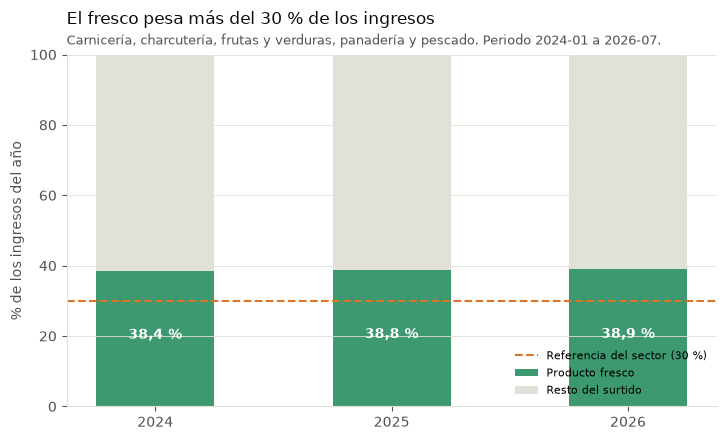

In [19]:
todo = completo.copy()
todo["fresco"] = todo["departamento"].isin(DEP_FRESCOS)

pct_año = (todo.groupby("año")
            .apply(lambda g: 100 * g.loc[g["fresco"], "total_venta"].sum() / g["total_venta"].sum(),
                   include_groups=False))
pct_total = 100 * todo.loc[todo["fresco"], "total_venta"].sum() / todo["total_venta"].sum()

print("Peso del producto fresco sobre los ingresos\n")
for a in AÑOS:
    print(f"  {a} : {num(pct_año.loc[a], 1)} %")
print(f"  ---")
print(f"  31 meses : {num(pct_total, 1)} %      referencia del sector: 30 %")

# Sensibilidad a la definición.
def peso(deps):
    m = todo["departamento"].isin(deps)
    return 100 * todo.loc[m, "total_venta"].sum() / todo["total_venta"].sum()

variantes = {
    "núcleo (carnicería + charcutería + frutas + panadería + pescado)": DEP_FRESCOS,
    "+ lácteos": DEP_FRESCOS + ["LACTEOS"],
    "− panadería (si se cuenta como industrial)": [d for d in DEP_FRESCOS if d != "PANADERIA PASTELERIA"],
    "− charcutería libre servicio": [d for d in DEP_FRESCOS if d != "CHARCUTERIA L.S"],
}
print("\nSensibilidad a la definición (31 meses)\n")
for etiqueta, deps in variantes.items():
    print(f"  {etiqueta:<58} {num(peso(deps), 1)} %")



# --- Gráfica: fresco vs no fresco por año, con la línea del 30 % ----------
x = np.arange(len(AÑOS))
fresco_y = [pct_año.loc[a] for a in AÑOS]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(x, fresco_y, width=0.5, color=VERDE, label="Producto fresco")
ax.bar(x, [100 - v for v in fresco_y], bottom=fresco_y, width=0.5, color=GRID,
       label="Resto del surtido")
ax.axhline(30, color=NARANJA, lw=1.5, ls="--", label="Referencia del sector (30 %)")
for xi, v in zip(x, fresco_y):
    ax.text(xi, v / 2, f"{num(v, 1)} %", ha="center", color="white", fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([str(a) for a in AÑOS])
ax.set_ylabel("% de los ingresos del año")
ax.set_ylim(0, 100)
ax.set_title("El fresco pesa más del 30 % de los ingresos",
             color=TINTA, loc="left", pad=22)
ax.text(0, 1.02, "Carnicería, charcutería, frutas y verduras, panadería y pescado. "
        f"Periodo {MESES[0]} a {MESES[-1]}.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "frescos-vs-referencia", VENTANA_COMPLETA)
plt.show()

El fresco pesa el 38,7 % de los ingresos, por encima del 30 %
de referencia, y se mantiene por encima en todas las variantes de la
definición. La tienda cumple el patrón del sector con holgura.

## 6 · Facturación nominal frente a real

La venta sube en euros corrientes. Para saber cuánto de esa subida es
**precio** y cuánto es **volumen** hay que descontar la inflación.

**Deflactor: un índice de precios con base enero de 2024 = 100**, construido
como `IPC_t / IPC_ene-2024` con el IPC de **alimentos y bebidas no alcohólicas
de Almería** del INE, que es a su vez un índice de Laspeyres ponderado por la
cesta de consumo. Enero de 2024 es el primer mes con datos, así que todo lo real
queda en euros de ese mes.

**A impuestos constantes:** los tipos de IVA de los alimentos cambiaron cinco
veces por ley dentro de la ventana, y el IPC mide precios **con** impuestos
mientras que la venta de la tienda es **base imponible**. Sin neutralizarlo, la
retirada de la rebaja temporal del IVA entraría en el índice como si fuera
inflación. La corrección es `IPC × (1 + tipo_referencia) / (1 + tipo_efectivo)`,
con el tipo efectivo que declara el propio cierre Z, y se aplica **antes** de
llevar la base a enero de 2024.

> Esto describe la evolución de **lo que recoge el diario por artículo**. El
> crecimiento del **negocio** —venta neta, afluencia, ticket medio— se mide en
> el [notebook 03](03-modelado-serie-semanal.ipynb).

El apartado termina **partiendo el crecimiento en dos**: cuánto es *volumen*
—más producto vendido— y cuánto es *precio* —la inflación de los alimentos—.

**El reparto se hace en diferencias logarítmicas.** La identidad
`Δln(nominal) = Δln(real) + Δln(precio)` es **exacta y aditiva**, mientras que
la versión aritmética (`%nominal ≈ %volumen + %precio`) es solo una
aproximación: el término cruzado, de una décima de punto en esta ventana, se
colaría en el efecto precio. El titular se da en **porcentaje** para que se
lea; solo el reparto va en logaritmos, que para variaciones de este tamaño
coinciden con los puntos porcentuales hasta la décima.

Índice de precios · alimentos y bebidas no alcohólicas de Almería, base 2024-01 = 100
(cociente IPC_t / IPC(ene-2024) del índice ponderado del INE, a impuestos
 constantes; la última columna, sin la corrección de los cambios de IVA)



,índice (ene-2024 = 100),índice sin corregir el IVA
periodo,,
2024-01,"100,00","100,00"
2025-01,"100,35","101,60"
2026-01,"103,26","104,54"
2026-07,"102,70","103,98"



Venta de artículos sumada de enero a julio — nominal frente a real
(real = nominal ÷ índice de precios, base 2024-01 = 100, a impuestos constantes)



,nominal (€ corrientes),real (€ constantes de 2024-01),lo que se lleva la inflación (€)
año,,,
2024,443.840,442.393,1.447
2025,459.067,451.950,7.117
2026,473.089,457.865,15.224



De dónde sale el crecimiento — volumen frente a precio
(diferencias logarítmicas, en puntos; Δln volumen + Δln precio = Δln nominal,
 exacto al redondeo. La última fila es todo el periodo; las de arriba, año
 contra año)



,Δln nominal,Δln volumen,Δln precio
enero-julio,,,
2024 → 2025,"+3,37","+2,14","+1,24"
2025 → 2026,"+3,01","+1,30","+1,71"
2024 → 2026,"+6,38","+3,44","+2,94"


El periodo entero. De 2024 a 2026 —enero-julio, dos años— la venta que capta
el diario por artículo sube +6,6 % en euros corrientes (+6,4 en
log-puntos). El reparto, en diferencias logarítmicas: 54 % del
crecimiento es volumen —más producto vendido— y 46 % es precio
—inflación de alimentos—: casi mitad y mitad, con el volumen algo por delante.

Y la mezcla se da la vuelta año a año: en 2025 el crecimiento fue sobre todo
volumen (+2,1 frente a +1,2 de precio, en log-puntos); en 2026,
con la inflación apretando, ya pesa más el precio (+1,3 frente a +1,7).

2025 → 2026 en euros: de los 14.022 € más que factura el
   informe, unos 7.962 € son subida de precios y unos 6.060 € más producto
   (43 % volumen, 57 % precio), según el reparto logarítmico.

   El escalón de IVA, aislado: con el índice sin corregir el efecto
   Precio del periodo saldría +4,21 en vez de +2,94 log-puntos, y el volumen
   +2,17 en vez de +3,44. Esos 1,26 puntos de diferencia son la retirada
   de la rebaja del IVA a 

  guardada 02-facturacion-nominal-vs-real-2024-01_2026-07.png / .svg


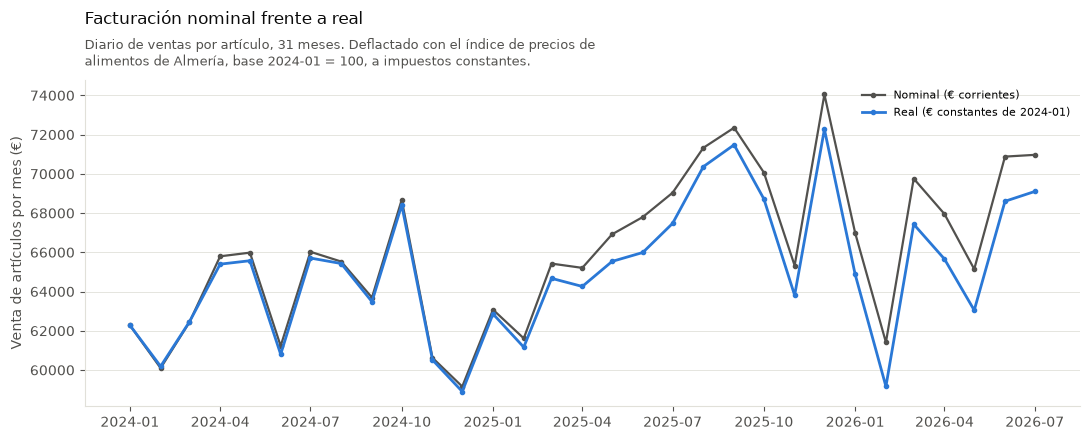

  guardada 02-crecimiento-volumen-vs-precio-2024-01_2026-07.png / .svg


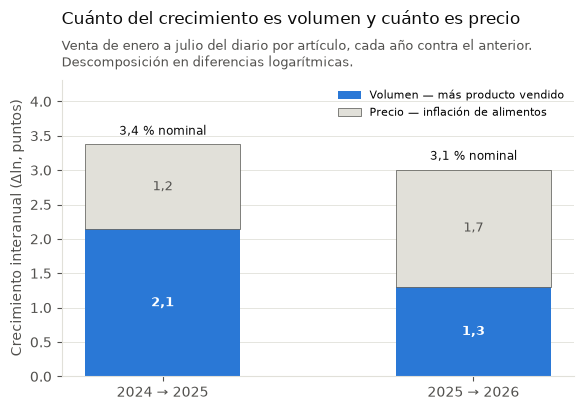

In [20]:
# El IPC de alimentos y bebidas no alcohólicas de Almería, a impuestos
# constantes, ya está en la serie semanal (`ipc_alimentos_ic`, un índice de
# Laspeyres ponderado por la cesta ecoicop del INE).
ss = pd.read_parquet("../datos_limpio/serie_semanal.parquet")
ss["mes"] = ss["periodo_inicio"].dt.strftime("%Y-%m")
ipc_ic_mes = ss.groupby("mes")["ipc_alimentos_ic"].mean()
ipc_raw_mes = ss.groupby("mes")["ipc_alimentos"].mean()

mens = (CATALOGO.groupby("periodo")["total_venta"].sum().rename("nominal").to_frame())
mens["ipc_ic"] = mens.index.map(ipc_ic_mes)
mens["ipc_raw"] = mens.index.map(ipc_raw_mes)

# --- El deflactor: índice de precios con base enero de 2024 = 100 ---------
# `I_t = 100 · IPC_t / IPC_ene-2024`.
BASE = MESES[0]                       # "2024-01", primer mes con dato
mens["indice_precios"] = 100 * mens["ipc_ic"] / mens["ipc_ic"].iloc[0]
mens["indice_precios_crudo"] = 100 * mens["ipc_raw"] / mens["ipc_raw"].iloc[0]
mens["real"] = mens["nominal"] / (mens["indice_precios"] / 100)
mens["real_crudo"] = mens["nominal"] / (mens["indice_precios_crudo"] / 100)

puntos = [BASE, f"{AÑOS[0] + 1}-01", f"{AÑOS[-1]}-01", MESES[-1]]
idx = mens.loc[[p for p in puntos if p in mens.index],
               ["indice_precios", "indice_precios_crudo"]].copy()
idx.columns = ["índice (ene-2024 = 100)", "índice sin corregir el IVA"]
print(f"Índice de precios · alimentos y bebidas no alcohólicas de Almería, "
      f"base {BASE} = 100")
print("(cociente IPC_t / IPC(ene-2024) del índice ponderado del INE, a impuestos")
print(" constantes; la última columna, sin la corrección de los cambios de IVA)\n")
display(idx.round(2))

# Comparación interanual enero-julio (los meses completos en los tres años),
# como en la deflactación.
m17 = [f"{a}-{m:02d}" for a in AÑOS for m in range(1, 8)]
ej = mens[mens.index.isin(m17)].copy()
ej["año"] = ej.index.str[:4].astype(int)
tab = ej.groupby("año")[["nominal", "real", "real_crudo"]].sum()

tabla_nr = pd.DataFrame({
    "nominal (€ corrientes)": tab["nominal"].map(lambda v: num(v, 0)),
    f"real (€ constantes de {BASE})": tab["real"].map(lambda v: num(v, 0)),
    "lo que se lleva la inflación (€)": (tab["nominal"] - tab["real"]).map(lambda v: num(v, 0)),
}, index=tab.index)
print("\nVenta de artículos sumada de enero a julio — nominal frente a real")
print(f"(real = nominal ÷ índice de precios, base {BASE} = 100, a impuestos constantes)\n")
display(tabla_nr)

# --- Descomposición en diferencias logarítmicas ----------------------------
# La identidad Δln(nominal) = Δln(real) + Δln(precio) es exacta y aditiva: el
# índice implícito de precios es, por definición, nominal / real, así que su
# variación logarítmica cierra la suma sin residuo ni término cruzado.
def _dln(s, i, j):
    return 100 * np.log(s.iloc[j] / s.iloc[i])


def _pct(s, i, j):
    return 100 * (s.iloc[j] / s.iloc[i] - 1)


pasos = []
for i in range(1, len(tab)):
    a0, a1 = int(tab.index[i - 1]), int(tab.index[i])
    dln_n = _dln(tab["nominal"], i - 1, i)
    dln_v = _dln(tab["real"], i - 1, i)
    pasos.append((a0, a1, _pct(tab["nominal"], i - 1, i), dln_n, dln_v, dln_n - dln_v))

if pasos:
    n = len(tab) - 1
    dln_nT = _dln(tab["nominal"], 0, n)
    dln_vT = _dln(tab["real"], 0, n)
    total = (int(tab.index[0]), int(tab.index[-1]),
             _pct(tab["nominal"], 0, n), dln_nT, dln_vT, dln_nT - dln_vT)

    desc = pd.DataFrame(
        [(f"{a0} → {a1}", num(gn, 2, signo=True), num(gv, 2, signo=True), num(gp, 2, signo=True))
         for a0, a1, pn, gn, gv, gp in pasos + [total]],
        columns=["enero-julio", "Δln nominal", "Δln volumen", "Δln precio"],
    ).set_index("enero-julio")
    print("\nDe dónde sale el crecimiento — volumen frente a precio")
    print("(diferencias logarítmicas, en puntos; Δln volumen + Δln precio = Δln nominal,")
    print(" exacto al redondeo. La última fila es todo el periodo; las de arriba, año")
    print(" contra año)\n")
    display(desc)

    a0, a1, pn_T, gn_T, gv_T, gp_T = total
    sh_vol = 100 * gv_T / gn_T
    print(f"El periodo entero. De {a0} a {a1} —enero-julio, dos años— la venta que capta")
    print(f"el diario por artículo sube {num(pn_T, 1, signo=True)} % en euros corrientes "
          f"({num(gn_T, 1, signo=True)} en")
    print(f"log-puntos). El reparto, en diferencias logarítmicas: {num(sh_vol, 0)} % del")
    print(f"crecimiento es volumen —más producto vendido— y {num(100 - sh_vol, 0)} % es precio")
    print("—inflación de alimentos—: casi mitad y mitad, con el volumen algo por delante.")
    print()
    y1, gv_1, gp_1 = pasos[0][1], pasos[0][4], pasos[0][5]
    y2, gv_2, gp_2, gn_2 = pasos[-1][1], pasos[-1][4], pasos[-1][5], pasos[-1][3]
    print(f"Y la mezcla se da la vuelta año a año: en {y1} el crecimiento fue sobre todo")
    print(f"volumen ({num(gv_1, 1, signo=True)} frente a {num(gp_1, 1, signo=True)} de precio, "
          f"en log-puntos); en {y2},")
    print(f"con la inflación apretando, ya pesa más el precio ({num(gv_2, 1, signo=True)} "
          f"frente a {num(gp_2, 1, signo=True)}).")

    # En euros: se reparte el incremento nominal del último tramo según la
    # descomposición logarítmica.
    eur_nom = tab["nominal"].iloc[-1] - tab["nominal"].iloc[-2]
    eur_vol = eur_nom * gv_2 / gn_2
    eur_pre = eur_nom - eur_vol
    print(f"\n{pasos[-1][0]} → {y2} en euros: de los {num(eur_nom, 0)} € más que factura el")
    print(f"   informe, unos {num(eur_pre, 0)} € son subida de precios y unos {num(eur_vol, 0)} € "
          f"más producto")
    print(f"   ({num(100 * eur_vol / eur_nom, 0)} % volumen, {num(100 * eur_pre / eur_nom, 0)} % "
          f"precio), según el reparto logarítmico.")

    # Cuánto del efecto precio es el escalón fiscal, no inflación: se
    # rehace la descomposición del periodo con el índice sin corregir el IVA.
    gv_raw = _dln(tab["real_crudo"], 0, n)
    gp_raw = gn_T - gv_raw
    print(f"\n   El escalón de IVA, aislado: con el índice sin corregir el efecto")
    print(f"   Precio del periodo saldría {num(gp_raw, 2, signo=True)} en vez de "
          f"{num(gp_T, 2, signo=True)} log-puntos, y el volumen")
    print(f"   {num(gv_raw, 2, signo=True)} en vez de {num(gv_T, 2, signo=True)}. Esos "
          f"{num(gp_raw - gp_T, 2)} puntos de diferencia son la retirada")
    print(f"   de la rebaja del IVA a los alimentos —encareció la cesta sin que la tienda")
    print(f"   ingresara un euro más—, no inflación. Por eso el índice va a impuestos")
    print(f"   constantes.")

    print("\n   Cuidado: esto no es el crecimiento del negocio. El diario por artículo no ve")
    print("   los genéricos de departamento ni los albaranes, y va a resolución mensual.")
    print("   El crecimiento de la venta neta del cierre Z para el mismo tramo ene-jul se")
    print("   calcula en comprobar_cifras.py y se reporta en la memoria; el")
    print("   notebook 03 mide la tendencia de las 135 semanas y la descomposición")
    print("   afluencia / ticket medio.")

infl = mens["indice_precios"].iloc[-1] - 100
infl_raw = mens["indice_precios_crudo"].iloc[-1] - 100
print(f"\n   Inflación acumulada de la ventana (índice ene-2024 = 100 → "
      f"{num(mens['indice_precios'].iloc[-1], 2)}):")
print(f"   {num(infl, 2)} % a impuestos constantes ({num(infl_raw, 2)} % con el índice sin")
print(f"   corregir — la diferencia es el escalón fiscal de los cambios de IVA, que no lo pagó la tienda).")


# --- Gráfica: nominal vs real -------------------------------------------
x = pd.to_datetime(mens.index + "-01")
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x, mens["nominal"], color=TINTA_SEC, lw=1.6, marker="o", ms=3, label="Nominal (€ corrientes)")
ax.plot(x, mens["real"], color=AZUL, lw=2, marker="o", ms=3,
        label=f"Real (€ constantes de {BASE})")
ax.set_ylabel("Venta de artículos por mes (€)")
ax.set_title("Facturación nominal frente a real", color=TINTA, loc="left", pad=40)
ax.text(0, 1.03, f"Diario de ventas por artículo, {len(MESES)} meses. Deflactado con "
        f"el índice de precios de\nalimentos de Almería, base {BASE} = 100, a impuestos "
        "constantes.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "facturacion-nominal-vs-real", VENTANA_COMPLETA)
plt.show()


# --- Gráfica: el crecimiento, partido en volumen y precio (log-puntos) -----
if len(pasos) >= 1:
    etq = [f"{a0} → {a1}" for a0, a1, *_ in pasos]
    vol = [p[4] for p in pasos]     # Δln volumen
    pre = [p[5] for p in pasos]     # Δln precio
    pct = [p[2] for p in pasos]     # nominal en %  (para la etiqueta de arriba)
    xb = np.arange(len(pasos))
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.set_axisbelow(True)
    ax.bar(xb, vol, width=0.5, color=AZUL, label="Volumen — más producto vendido")
    ax.bar(xb, pre, width=0.5, bottom=vol, color=GRID, edgecolor=TINTA_SEC,
           linewidth=0.5, label="Precio — inflación de alimentos")
    for xi, (v, p, pc) in enumerate(zip(vol, pre, pct)):
        ax.text(xi, v / 2, f"{num(v, 1)}", ha="center", va="center",
                color="white", fontsize=9, fontweight="bold")
        ax.text(xi, v + p / 2, f"{num(p, 1)}", ha="center", va="center",
                color=TINTA_SEC, fontsize=9)
        ax.text(xi, v + p + 0.10, f"{num(pc, 1)} % nominal", ha="center",
                va="bottom", fontsize=8.5, color=TINTA)
    ax.set_xticks(xb)
    ax.set_xticklabels(etq)
    ax.set_ylabel("Crecimiento interanual (Δln, puntos)")
    ax.set_ylim(0, max(v + p for v, p in zip(vol, pre)) * 1.28)
    ax.set_title("Cuánto del crecimiento es volumen y cuánto es precio",
                 color=TINTA, loc="left", pad=40)
    ax.text(0, 1.03, "Venta de enero a julio del diario por artículo, cada "
            "año contra el anterior.\nDescomposición en diferencias logarítmicas.",
            transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    guardar(fig, "crecimiento-volumen-vs-precio", VENTANA_COMPLETA)
    plt.show()

## 7 · La nevera de bebidas frías

La tienda vende bebida fría con **códigos propios**, distintos de los del
lineal: `REFRESCO FRIO 33 CL`, `CERVEZA FRIA LATA 33 CL` y dos líneas de
`SUPLEMENTO BEBIDA FRIA`. Nueve códigos.

**Están fuera del análisis de rentabilidad** porque **el código no identifica
el producto**: «REFRESCO FRIO 33 CL» es cualquier lata de la nevera, e incluso
entre las siete latas de refresco de 33 cl con que se compara, el coste va de
0,23 € a 0,61 €. No se puede calcular *su* margen, pero sí el
**diferencial**, que es la pregunta de negocio: ¿cuánto añade vender el mismo
envase frío?

> **Dato de la tienda:** la nevera está **cedida por un proveedor** y la tienen
> **todo el año**. No hay amortización que imputar, y como no se enchufa solo
> en verano, la estacionalidad de más abajo es **de demanda**.

In [21]:
# Los códigos (FRIOS_BEBIDA, FRIOS_SUPLEMENTO) están definidos en la celda de
# constantes y ya se han excluido de surtido en el §3.
frio = CATALOGO[CATALOGO["cod_articulo"].isin(FRIOS_BEBIDA)]
sup = CATALOGO[CATALOGO["cod_articulo"].isin(FRIOS_SUPLEMENTO)]

resumen_frio = (frio.groupby("cod_articulo")
                .agg(artículo=("descripcion", "last"), meses=("periodo", "nunique"),
                     unidades=("unidades", "sum"), venta=("total_venta", "sum"))
                .sort_values("venta", ascending=False))
print(f"Bebida fría · {len(MESES)} meses")
print(resumen_frio.to_string(index=False))

u_frio, v_frio = frio["unidades"].sum(), frio["total_venta"].sum()
print(f"\n  bebida fría : {num(u_frio, 0)} unidades · {num(v_frio)} € "
      f"({num(100 * v_frio / v_catalogo, 2)} % de la venta del catálogo)")
print(f"  suplemento  : {num(sup['unidades'].sum(), 0)} cobros · {num(sup['total_venta'].sum())} €")

Bebida fría · 31 meses
               artículo  meses  unidades    venta
    REFRESCO FRIO 33 CL     31  6.659,00 6.603,96
CERVEZA FRIA LATA 33 CL     31  4.629,00 3.810,26
       CERVEZA FRIA 1 L     14  1.304,00 2.155,20
    MONSTER FRIO 500 ML     31    728,00 1.198,84
CERVEZA FRIA LATA 50 CL     30    976,00   967,29
  BOTELLA AGUA FRIA 1,5     29    827,00   751,84
   RED BULL FRIO 355 ML     11     63,00   122,36

  bebida fría : 15.186 unidades · 15.609,75 € (0,76 % de la venta del catálogo)
  suplemento  : 8.316 cobros · 1.259,53 €


El suplemento se cuenta aparte: no es mercancía, es el recargo por
servir frío. No tiene coste de compra porque no hay nada que comprar.

In [22]:
# El sobreprecio del frío: el mismo envase, en dos sitios.
BANDA_TRAMO = 0.30
POOL_FRIO = {
    "Refresco lata 33": ("84887", ["1623", "428016", "12783", "7460", "428012", "428030", "428017"]),
    "Cerveza lata 33":  ("84891", ["431002", "1988", "11206", "36026", "431018", "70697", "37723"]),
    "Cerveza lata 50":  ("84890", ["431003"]),
    "Cerveza 1 L":      ("84888", ["431001", "1936"]),
    "Energética":       ("84889", ["428033", "10526", "15987", "11394", "18730", "136212", "118551", "1440"]),
}

por_cod = CATALOGO.groupby("cod_articulo").agg(
    u=("unidades", "sum"), v=("total_venta", "sum"), c=("tarifa_costo", "median"))
por_cod["pu"] = por_cod["v"] / por_cod["u"]


def emparejar(banda):
    out = []
    for categoria, (cod_frio, pool) in POOL_FRIO.items():
        f = por_cod.loc[cod_frio]
        L = por_cod.loc[[c for c in pool if c in por_cod.index]]
        sel = L[(L["c"] >= f["c"] * (1 - banda)) & (L["c"] <= f["c"] * (1 + banda))]
        if sel.empty:
            continue
        p_l = sel["v"].sum() / sel["u"].sum()
        c_l = (sel["c"] * sel["u"]).sum() / sel["u"].sum()
        out.append({"categoría": categoria, "u. frías": f["u"], "€ frío": f["pu"],
                    "€ lineal": p_l, "sobreprecio (%)": 100 * (f["pu"] / p_l - 1),
                    "margen frío (%)": 100 * (f["pu"] - c_l) / f["pu"],
                    "margen lineal (%)": 100 * (p_l - c_l) / p_l, "refs": len(sel),
                    "_uf": f["u"], "_vf": f["v"], "_ci": c_l * f["u"],
                    "_vl": sel["v"].sum(), "_cl": (sel["c"] * sel["u"]).sum(), "_ul": sel["u"].sum()})
    return pd.DataFrame(out)


def agregado(t):
    vf, ci = t["_vf"].sum(), t["_ci"].sum()
    vl, cl, ul, uf = t["_vl"].sum(), t["_cl"].sum(), t["_ul"].sum(), t["_uf"].sum()
    return 100 * (vf - ci) / vf, 100 * (vl - cl) / vl, (vf - ci) - uf * (vl - cl) / ul


pares = emparejar(BANDA_TRAMO)
print(pares.drop(columns=[c for c in pares if c.startswith("_")]).round(2).to_string(index=False))
mg_frio, mg_lineal, extra = agregado(pares)
print(f"\n  margen de la nevera : {num(mg_frio, 1)} %   (coste imputado al del mismo envase y tramo)")
print(f"  margen del lineal   : {num(mg_lineal, 1)} %")
print(f"  la nevera multiplica el margen por {num(mg_frio / mg_lineal, 1)}")
print(f"  margen extra que aporta el frío : {num(extra)} € en {len(MESES)} meses")

print("\nSensibilidad a la anchura de la banda:")
for b in (0.20, 0.25, 0.30, 0.40, 0.50):
    a, c, e = agregado(emparejar(b))
    marca = "  <- la usada" if abs(b - BANDA_TRAMO) < 1e-9 else ""
    print(f"  ±{b:.0%}   factor {num(a / c, 1)}x   margen extra {num(e)} €{marca}")

       categoría  u. frías  € frío  € lineal  sobreprecio (%)  margen frío (%)  margen lineal (%)  refs
Refresco lata 33  6.659,00    0,99      0,75            32,31            44,52              26,59     5
 Cerveza lata 33  4.629,00    0,82      0,54            52,68            52,47              27,43     5
 Cerveza lata 50    976,00    0,99      0,47           112,90            62,67              20,52     1
     Cerveza 1 L  1.304,00    1,65      1,13            46,65            48,32              24,21     2
      Energética    728,00    1,65      1,31            25,54            46,80              33,22     6

  margen de la nevera : 48,5 %   (coste imputado al del mismo envase y tramo)
  margen del lineal   : 26,6 %
  la nevera multiplica el margen por 1,8
  margen extra que aporta el frío : 4.583,36 € en 31 meses

Sensibilidad a la anchura de la banda:


  ±20%   factor 1,7x   margen extra 3.624,97 €
  ±25%   factor 1,8x   margen extra 3.844,84 €
  ±30%   factor 1,8x   margen extra 4.583,36 €  <- la usada
  ±40%   factor 1,8x   margen extra 4.590,46 €
  ±50%   factor 1,8x   margen extra 4.590,46 €


El factor se mueve entre 1,7 y 1,8 en todo el rango; el importe entre
unos 3.600 y 4.600 €. Se cita el de la banda elegida con su rango.
El agua de 1,5 L queda fuera: es el único código frío sin `tarifa_costo`
en ninguna columna, así que no hay tramo con el que anclarla.

In [23]:
# ¿Qué parte de las latas que vende la tienda salen frías?
PACK_CONFIRMADO = {"5540": 12, "7804": 12, "72043": 12,
                   "17027": 12, "37976": 12, "48491": 12, "9573": 12,
                   "30338": 24}   # 30338: el precio no cuadra con 24, ver abajo

CATEGORIAS = {
    "Refresco lata 33": ("84887",
                         ["1623", "428016", "12783", "7460", "428012", "428030", "428017"],
                         ["5540", "7804", "72043"]),
    "Cerveza lata 33":  ("84891",
                         ["431002", "1988", "11206", "36026", "431018", "70697", "37723"],
                         ["17027", "37976", "48491", "9573", "30338"]),
}

p = CATALOGO.groupby("cod_articulo").agg(u=("unidades", "sum"))
filas = []
for cat, (cod_frio, sueltos, packs) in CATEGORIAS.items():
    u_frias = p.loc[cod_frio, "u"]
    u_sueltas = p.loc[sueltos, "u"].sum()
    u_pack = sum(p.loc[k, "u"] * PACK_CONFIRMADO[k] for k in packs)
    cuota_sin = 100 * u_frias / (u_frias + u_sueltas)
    cuota_con = 100 * u_frias / (u_frias + u_sueltas + u_pack)
    filas.append({"categoría": cat, "frías": u_frias, "sueltas": u_sueltas,
                  "en pack": u_pack, "cuota sin packs (%)": cuota_sin,
                  "cuota con packs (%)": cuota_con})
cuotas = pd.DataFrame(filas)
print(cuotas.round(1).to_string(index=False))

       categoría    frías    sueltas   en pack  cuota sin packs (%)  cuota con packs (%)
Refresco lata 33 6.659,00  31.266,00 10.488,00                17,60                13,80
 Cerveza lata 33 4.629,00 106.240,00 30.972,00                 4,20                 3,30


La lectura que importa: la nevera es muy rentable sobre una porción
pequeña del envase que vende la tienda —del orden del 3 % de las cervezas
y el 13 % de los refrescos—. Un margen doble sobre el 3 % no es lo mismo
que sobre el 30 %, y las dos cosas hay que decirlas juntas.

Aviso: la cerveza Alhambra 1925 (30338) se informó como envase de 24, pero a 24 su
coste unitario saldría un 45 % por debajo de la lata Alhambra normal, y
1925 es la gama alta. A 12 sale un +9,5 %, que es lo esperable. Se
conserva el 24 que dio la tienda; mueve la cuota de la cerveza < 0,1 pp.

  guardada 02-bebida-fria-estacionalidad-2024-01_2026-07.png / .svg


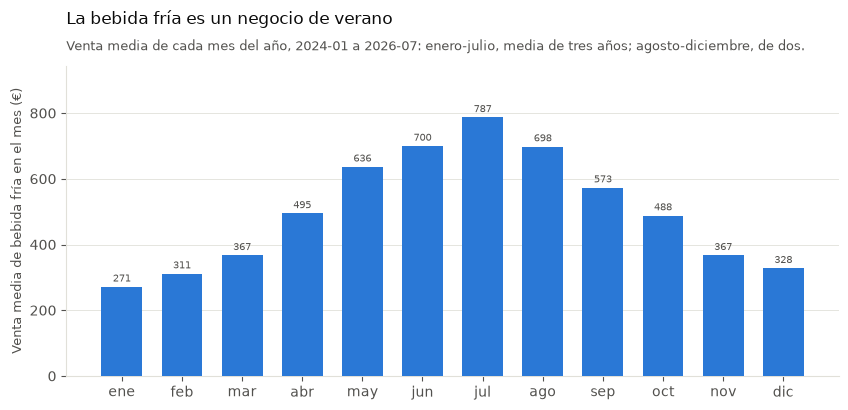

  mes más flojo  (ene) : 271 € de media
  mes más fuerte (jul) : 787 € de media  (2,9x el mínimo)
  media mensual : verano (jun-sep) 689 €  ·  resto del año 408 €


In [24]:
# ¿Es estacional? La nevera está todo el año, así que esto es demanda.
frio_mes = frio.assign(m=frio["periodo_inicio"].dt.month).groupby("m")["total_venta"].sum()
anios_mes = CATALOGO.assign(m=CATALOGO["periodo_inicio"].dt.month).groupby("m")["periodo_inicio"].agg(lambda s: s.dt.year.nunique())
frio_media = frio_mes / anios_mes
tot_mes = CATALOGO.assign(m=CATALOGO["periodo_inicio"].dt.month).groupby("m")["total_venta"].sum()

MESES_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul",
            "ago", "sep", "oct", "nov", "dic"]

fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.bar(frio_media.index, frio_media.values, color=AZUL, width=0.68, zorder=3)
ax.bar_label(barras, labels=[num(v, 0) for v in frio_media.values], padding=2,
             fontsize=7.5, color=TINTA_SEC)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES_ES)
ax.set_ylabel("Venta media de bebida fría en el mes (€)", fontsize=9)
ax.set_ylim(0, frio_media.max() * 1.20)
ax.set_title("La bebida fría es un negocio de verano", color=TINTA, loc="left", pad=30)
ax.text(0, 1.04, f"Venta media de cada mes del año, {MESES[0]} a {MESES[-1]}: "
        "enero-julio, media de tres años; agosto-diciembre, de dos.",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.grid(axis="x", visible=False)
fig.tight_layout()
guardar(fig, "bebida-fria-estacionalidad", VENTANA_COMPLETA)
plt.show()

ver = [6, 7, 8, 9]
e_ver = frio_media.loc[ver].mean()
e_res = frio_media.drop(ver).mean()
c_ver = 100 * frio_mes.loc[ver].sum() / tot_mes.loc[ver].sum()
c_res = 100 * (frio_mes.sum() - frio_mes.loc[ver].sum()) / (tot_mes.sum() - tot_mes.loc[ver].sum())
print(f"  mes más flojo  ({MESES_ES[frio_media.idxmin() - 1]}) : {num(frio_media.min(), 0)} € de media")
print(f"  mes más fuerte ({MESES_ES[frio_media.idxmax() - 1]}) : {num(frio_media.max(), 0)} € de media  "
      f"({num(frio_media.max() / frio_media.min(), 1)}x el mínimo)")
print(f"  media mensual : verano (jun-sep) {num(e_ver, 0)} €  ·  resto del año {num(e_res, 0)} €")

Y no es solo que la tienda venda más en verano: la bebida fría pasa del 0,63 %
de la venta el resto del año al 1,03 % en verano. Como la nevera está
enchufada los doce meses, esta curva mide al cliente, no la disponibilidad.

## 8 · Promociones: el margen en oferta

La columna `Of.` marca **el artículo**, no el mes concreto en que estuvo en
promoción, así que el «% de venta en oferta» es un techo. Por eso no entra en
el modelo de previsión. Aquí se usa para lo único que sirve: comparar el margen
de los artículos marcados con el del resto.

Año móvil — filas en promoción: 825 de 35.728 (2,3 %),  14.387,62 € (1,8 % de la venta)

Margen ponderado sin promoción : 29,49 %
Margen ponderado en promoción  : 16,37 %
Diferencia                     : +13,12 pp



Por departamento:
                              % venta en oferta  margen en oferta (%)  margen sin oferta (%)  dif (pp)
departamento                                                                                          
L.S CARNICO Y SALAZONES                  100,00                 22,63                    NaN       NaN
CONGELADOS                                 3,62                 21,99                  30,06      8,07
CARNICERIA                                 3,28                 21,40                  35,63     14,23
CHARCUTERIA CORTE                          2,41                  9,70                  26,80     17,10
BEBIDAS                                    2,34                 15,85                  26,66     10,81
DROGUERIA Y PERFUMERIA                     1,82                 17,39                  29,53     12,14
ULTRAMARINOS                               1,50                 10,25                  25,75     15,50
FRUTAS Y VERDURAS                          0,97       

  guardada 02-margen-oferta-vs-sin-oferta-2025-08_2026-07.png / .svg


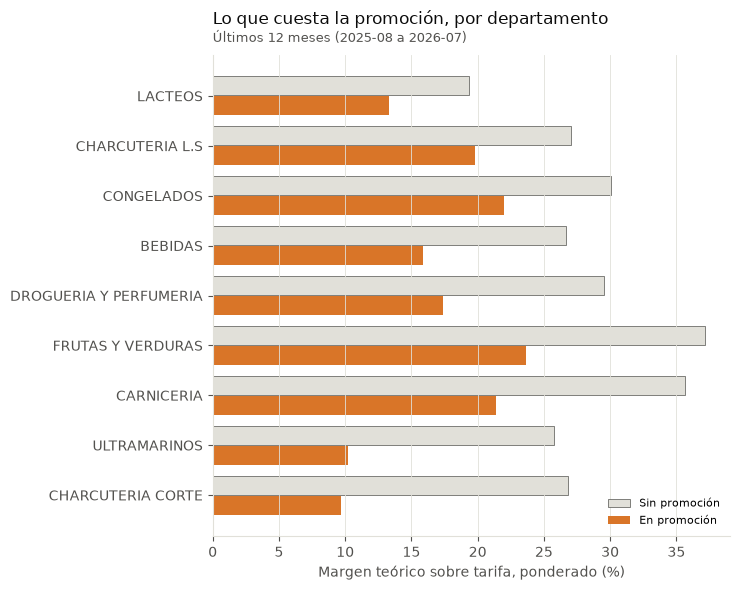

In [25]:
n_of = int(AÑO_MOVIL["oferta"].sum())
v_of = AÑO_MOVIL.loc[AÑO_MOVIL["oferta"], "total_venta"].sum()
print(f"Año móvil — filas en promoción: {num(n_of, 0)} de {num(len(AÑO_MOVIL), 0)} "
      f"({num(100 * n_of / len(AÑO_MOVIL), 1)} %),  {num(v_of)} € "
      f"({num(100 * v_of / AÑO_MOVIL['total_venta'].sum(), 1)} % de la venta)")

o, n = AÑO_MOVIL[AÑO_MOVIL["oferta"]], AÑO_MOVIL[~AÑO_MOVIL["oferta"]]
print(f"\nMargen ponderado sin promoción : {num(margen_ponderado(n), 2)} %")
print(f"Margen ponderado en promoción  : {num(margen_ponderado(o), 2)} %")
print(f"Diferencia                     : {num(margen_ponderado(n) - margen_ponderado(o), 2, signo=True)} pp")

ofertas = (AÑO_MOVIL.groupby("departamento")
           .apply(lambda g: pd.Series({
               "% venta en oferta": 100 * g.loc[g["oferta"], "total_venta"].sum() / g["total_venta"].sum(),
               "margen en oferta (%)": margen_ponderado(g[g["oferta"]]),
               "margen sin oferta (%)": margen_ponderado(g[~g["oferta"]]),
           }), include_groups=False))
ofertas["dif (pp)"] = ofertas["margen sin oferta (%)"] - ofertas["margen en oferta (%)"]
print("\nPor departamento:")
print(ofertas.sort_values("% venta en oferta", ascending=False).round(2).to_string())


# --- Gráfica: lo que cuesta la promoción, por departamento ----------------
comp_of = ofertas.dropna(subset=["dif (pp)"]).sort_values("dif (pp)", ascending=False)
y = np.arange(len(comp_of))
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(y + 0.2, comp_of["margen sin oferta (%)"], height=0.38, color=GRID,
        edgecolor=TINTA_SEC, linewidth=0.5, label="Sin promoción")
ax.barh(y - 0.2, comp_of["margen en oferta (%)"], height=0.38, color=NARANJA,
        label="En promoción")
ax.set_yticks(y)
ax.set_yticklabels(comp_of.index)
ax.set_xlabel("Margen teórico sobre tarifa, ponderado (%)")
ax.set_title("Lo que cuesta la promoción, por departamento",
             color=TINTA, loc="left", pad=22)
ax.text(0, 1.02, f"Últimos {MESES_AÑO_MOVIL} meses ({MESES_RECIENTES[0]} a {MESES_RECIENTES[-1]})",
        transform=ax.transAxes, color=TINTA_SEC, fontsize=9, va="bottom")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "margen-oferta-vs-sin-oferta", VENTANA_AÑO_MOVIL)
plt.show()


## 9 · Límites de este análisis

- **Todo el margen va sobre `SURTIDO`, algo menos del 99 % de la venta del
  catálogo** (la cobertura exacta la imprime el apartado 3). Lo que queda fuera
  —sin `tarifa_costo`, coste disparatado, venta cero, las dos bolsas de caja,
  los nueve códigos de bebida fría y los errores de coste— pesa poco. Los dos
  artículos comprados por caja y vendidos a granel se **corrigen** y sí entran.
- **`SURTIDO` es más estrecho que el `CATALOGO` del apartado 1.** El retrato de
  venta y permanencia va sobre el catálogo entero, y precio y margen, sobre
  `SURTIDO`; por eso los recuentos de artículos no coinciden.
- **`tarifa_costo` es el precio al que se compraría hoy el artículo**, sin
  portes ni rappel aparte (lo confirmó la tienda). La limitación que queda es
  de calidad de la ficha —tarifas que se actualizan tarde—, no de concepto.
- **No permite fijar precios con precisión**: el precio es un promedio mensual
  redondeado.
- **Los nombres de artículo llegan cortados** desde el informe en un 6,4 % de
  los casos.

La serie semanal, el crecimiento real del negocio y el modelo de previsión
están en el [notebook 03](03-modelado-serie-semanal.ipynb).